# Normalizing-Flow Photometric-Redshift Analysis

This notebook contains the DESI/Legacy photo-$z$ workflow used to train and evaluate a conditional normalizing flow, Random Forest (RF), and Quantile Random Forest (QRF), followed by PDF calibration and $N(z)$ reconstruction.

### Workflow
1. Load the training/testing catalogues and build photometric features.
2. Train/load the normalizing flow and generate posterior samples.
3. Train RF/QRF baselines and compare point estimates.
4. Evaluate feature saliency and probabilistic calibration.
5. Reconstruct the full-sample and tomographic $N(z)$ distributions.




## 1. Imports and helper functions
Core dependencies and reusable utilities for the flow, diagnostics, and sky-footprint plots.


In [1]:
import os
from time import time
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pylab as pl
import seaborn as sns
import torch
from torch.utils.data import DataLoader, TensorDataset
import pyro.distributions as dist
import pyro.distributions.transforms as T
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.table import Table, vstack
from astropy.io import fits
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from quantile_forest import RandomForestQuantileRegressor
from scipy.stats import wasserstein_distance
from scipy.spatial.distance import jensenshannon
from matplotlib.colors import LogNorm
from matplotlib.ticker import AutoMinorLocator, MultipleLocator, FormatStrFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


In [2]:
def plot_loss_train_eval(nll_train, nll_valid,title):
        plt.figure()
        plt.plot(nll_train, label="train")
        plt.plot(nll_valid, label="valid")
        plt.xlabel("Step / 100")
        plt.ylabel("Loss function")
        plt.title(title)
        plt.legend()
        print(np.mean(nll_train[50:75]),np.mean(nll_valid[200:250]))
        #plt.ylim(-5, 1)
        plt.savefig(f"lossfunction.png", format="png")
def train_validate_test_split( condition_data, x_data, itype ):
    split_range =  [ int( np.around( len(condition_data) * np.sum( np.array(split_fraction)[:i] ) ) ) for i
                     in range(len( split_fraction) + 1 ) ]           
    data_range = range(split_range[itype],split_range[itype+1])
    x1 = condition_data[data_range]
    x2 = x_data[data_range]
    return x1, x2
def get_mean_min_loglikelihood( dist_x2_given_x1, x1, x2 ):
    ln_p_x2_given_x1 = dist_x2_given_x1.condition(x1.detach().to(device)).log_prob(x2.detach().to(device))
    loss = -ln_p_x2_given_x1.mean()
    return loss
def model_training(x1_train, x2_train, x1_validate, x2_validate, output_model):
    dist_base = dist.Normal(
        torch.zeros(1).to(device),
        torch.ones(1).to(device)
    )
    Nconditions = x1_train.shape[1]
    x2_transform = torch.nn.ModuleList([
        T.conditional_spline(
            1,
            context_dim=Nconditions,
            hidden_dims=[32, 32, 32],
            bound=6.0
        )
        for _ in range(num_layers)
    ]).to(device)
    dist_x2_given_x1 = dist.ConditionalTransformedDistribution(
        dist_base,
        list(x2_transform)
    )
    modules = x2_transform
    optimizer = torch.optim.Adam(
        modules.parameters(),
        lr=lr,
        weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.MultiStepLR(
        optimizer,
        milestones=[change1, change2],
        gamma=0.1
    )
    train_loader = DataLoader(
        TensorDataset(x1_train, x2_train),
        batch_size=batch_size,
        shuffle=True
    )
    nll_train = []
    nll_valid = []
    best_val_loss = float("inf")
    patience_counter = 0
    t_start = time()
    for epoch in range(N_epochs):
        loss_train = []
        loss_valid = []
        for i, (x1_batch, x2_batch) in enumerate(train_loader):
            x1_batch = x1_batch.to(device)
            x2_batch = x2_batch.to(device)
            optimizer.zero_grad()
            loss = get_mean_min_loglikelihood(
                dist_x2_given_x1,
                x1_batch,
                x2_batch
            )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                modules.parameters(),
                max_norm=10.0
            )
            optimizer.step()
            dist_x2_given_x1.clear_cache()
            loss_train.append(loss.item())
            with torch.no_grad():
                val_loss = get_mean_min_loglikelihood(
                    dist_x2_given_x1,
                    x1_validate.to(device),
                    x2_validate.to(device)
                )
            loss_valid.append(val_loss.item())
            dist_x2_given_x1.clear_cache()
            if i % 100 == 0:
                print(
                    "%.3i \t%.5i/%.5i \t%.2f \t%.6f \t%.6f \t%.2e"
                    % (
                        epoch,
                        i,
                        len(train_loader),
                        (time() - t_start) / 60.0,
                        np.mean(loss_train),
                        np.mean(loss_valid),
                        optimizer.param_groups[0]["lr"]
                    ),
                    flush=True
                )

        scheduler.step()
        mean_train_loss = np.mean(loss_train)
        mean_valid_loss = np.mean(loss_valid)
        nll_train.append(mean_train_loss)
        nll_valid.append(mean_valid_loss)
        if mean_valid_loss < best_val_loss:
            best_val_loss = mean_valid_loss
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience_limit:
            print(
                f"\nEarly stopping at epoch {epoch}.\n"
                f"Best validation loss: {best_val_loss:.6f}"
            )
            break
    # save final model
    torch.save(
        {
            "model_state_dict": modules.state_dict(),
            "num_layers": num_layers,
            "Nconditions": Nconditions,
            "hidden_dims": [32, 32, 32],
            "bound": 6.0
        },
        output_model
    )
    print(f"Final model saved to {output_model}")
    return dist_x2_given_x1, nll_train, nll_valid
def test_sample_dist( x1_test, x2_test, zs, mean, std):
    x2_flow = np.zeros([ len(x2_test), Nsamples ])
    for isample in range(Nsamples):
        x2_flow[:, isample] = dist_x2_given_x1.condition(x1_test.to(device)).sample(torch.Size([len(x2_test)])).squeeze().detach().cpu().numpy()
    x2_flow = x2_flow*std + mean 
    z_maxp = np.zeros( [ len(x2_test[:,0]) ] )
    for i in range(len(x2_test)):    
        hist, bin_edges =  np.histogram( x2_flow[i,:], bins=2000, range=(0,2) ) 
        j = np.argmax(hist)
        z_maxp[i] = ( bin_edges[j+1] + bin_edges[j] ) / 2.
    z_median = np.median(x2_flow,axis=1)
    z_mean = np.mean(x2_flow,axis=1)
    err_std = np.std( x2_flow, axis=1 )
    err_68halfpc= ( np.percentile( x2_flow, 84, axis=1 ) - np.percentile( x2_flow, 16, axis=1 ) ) / 2 
#return Monte carlo samples,point estimation
    return x2_flow, z_maxp, z_median, z_mean, err_std, err_68halfpc  

def transmission(EBV):
    #Reden curve(DECAM_G,DECAM_R,DECAM_Z,wise_W1,wise_W2)
    Reden_curve=[3.214,2.165,1.211,1.263,1.088]
    G_transimission=10**(-0.4*Reden_curve[0]*EBV)
    R_transimission=10**(-0.4*Reden_curve[1]*EBV)
    Z_transimission=10**(-0.4*Reden_curve[2]*EBV)
    W1_transimission=10**(-0.4*Reden_curve[3]*EBV)
    W2_transimission=10**(-0.4*Reden_curve[4]*EBV)
    return  G_transimission,R_transimission,Z_transimission, W1_transimission,W2_transimission

def load_model(model_path):
    checkpoint = torch.load(
        model_path,
        map_location=device,
        weights_only=False
    )
    Nconditions = checkpoint["Nconditions"]
    num_layers_saved = checkpoint["num_layers"]
    hidden_dims = checkpoint["hidden_dims"]
    bound = checkpoint["bound"]
    dist_base = dist.Normal(
        torch.zeros(1).to(device),
        torch.ones(1).to(device)
    )
    x2_transform = torch.nn.ModuleList([
        T.conditional_spline(
            1,
            context_dim=Nconditions,
            hidden_dims=hidden_dims,
            bound=bound
        )
        for _ in range(num_layers_saved)
    ]).to(device)
    x2_transform.load_state_dict(
        checkpoint["model_state_dict"]
    )
    x2_transform.eval()
    dist_x2_given_x1 = dist.ConditionalTransformedDistribution(
        dist_base,
        list(x2_transform)
    )
    dist_x2_given_x1.clear_cache()
    return dist_x2_given_x1, x2_transform
def evaluate_saved_nll(model_path, x1_valid, x2_valid, batch_size=4096):
    model, modules = load_model(model_path)
    modules.eval()
    total_nll = 0.0
    total_n = 0
    with torch.no_grad():
        for i in range(0, len(x1_valid), batch_size):
            x1 = x1_valid[i:i+batch_size].to(device)
            x2 = x2_valid[i:i+batch_size].to(device)
            log_prob = model.condition(x1).log_prob(x2)
            total_nll -= log_prob.sum().item()
            total_n += log_prob.numel()
            model.clear_cache()
    return total_nll / total_n

In [3]:
def add_galactic_plane(ax, ra_center=180):

    # Galactic longitude along the Galactic plane: b = 0 deg
    l = np.linspace(0, 360, 2000)
    b = np.zeros_like(l)

    gal = SkyCoord(
        l=l * u.deg,
        b=b * u.deg,
        frame="galactic"
    )

    # Convert to equatorial coordinates
    eq = gal.icrs

    ra = eq.ra.deg
    dec = eq.dec.deg

    # Same RA transformation as your footprint
    ra_shift = ((ra - ra_center + 180.0) % 360.0) - 180.0

    x = np.radians(ra_shift)
    y = np.radians(dec)

    # Avoid connecting points across the Mollweide boundary
    jumps = np.abs(np.diff(x)) > np.pi

    x_plot = x.copy()
    y_plot = y.copy()

    x_plot[1:][jumps] = np.nan
    y_plot[1:][jumps] = np.nan

    ax.plot(
        x_plot,
        y_plot,
        linestyle="--",
        linewidth=1.0,
        alpha=0.8,
        label="Galactic plane",
        zorder=3
    )
def isotropic_radec(n):
    ra = np.random.uniform(0.0, 360.0, size=n)
    u = np.random.uniform(-1.0, 1.0, size=n)
    dec = np.degrees(np.arcsin(u))
    return ra, dec

def add_plane_enhancement(ra, dec, width_deg=10, strength=3.0, frac=0.3):
    n_extra = int(len(ra) * frac)
    ra_extra = np.random.uniform(0.0, 360.0, size=n_extra)
    dec_extra = np.random.normal(loc=0.0, scale=width_deg/strength, size=n_extra)
    dec_extra = np.clip(dec_extra, -90, 90)
    return np.concatenate([ra, ra_extra]), np.concatenate([dec, dec_extra])

def radec_hist_density(ra_deg, dec_deg, bins=(360, 180)):
    fig = plt.figure(figsize=(8, 5))
    plt.hist2d(ra_deg, dec_deg, bins=bins, range=[[0, 360], [-90, 90]])
    plt.xlabel("Right Ascension (deg)")
    plt.ylabel("Declination (deg)")
    plt.title("RA–Dec Density (2D histogram)")
    plt.colorbar(label="Counts")
    plt.tight_layout()
    return fig
def plot_patch_boundary(ax, ra_min, ra_max, dec_min, dec_max, color='red'):
    # Build rectangle edges
    ra = np.array([ra_min, ra_max, ra_max, ra_min, ra_min])
    dec = np.array([dec_min, dec_min, dec_max, dec_max, dec_min])

    # Wrap RA to [-180, 180]
    ra_wrap = ((ra + 180) % 360) - 180

    # Convert to radians
    ra_rad = -np.radians(ra_wrap)   # flip RA direction
    dec_rad = np.radians(dec)

    boundary=ax.plot(ra_rad, dec_rad, color=color, lw=1.8)
    return boundary
def radec_mollweide_density(ra_deg, dec_deg, nlon=360, nlat=180,ra_center=180):
    lon_edges_deg = np.linspace(-180, 180, nlon + 1)
    lat_edges_deg = np.linspace(-90, 90, nlat + 1)

    # Wrap RA into [-180, 180]
    lon_deg = ((ra_deg + 180.0) % 360.0) - 180.0

    # 2D histogram
    H, lon_e, lat_e = np.histogram2d(
        lon_deg, dec_deg,
        bins=[lon_edges_deg, lat_edges_deg]
    )

    # Convert bin edges to radians for Mollweide
    lon_edges_rad = -np.radians(lon_e)   # flip sign so RA increases to the left
    lat_edges_rad = np.radians(lat_e)

    LON, LAT = np.meshgrid(lon_edges_rad, lat_edges_rad, indexing="ij")

    fig = plt.figure(figsize=(6, 4))
    ax = fig.add_subplot(111, projection="mollweide")

    # Density map
    pcm = ax.pcolormesh(
        LON, LAT, H,
        shading="auto",
        cmap="Reds"
    )

    # Patch boundary: RA in [80, 160], Dec in [-15, 40]
    ra = np.array([80, 160, 160, 80, 80])
    dec = np.array([-15, -15, 40, 40, -15])

    ra_wrap = ((ra + 180.0) % 360.0) - 180.0
    ra_rad = -np.radians(ra_wrap)
    dec_rad = np.radians(dec)

    ax.plot(
    ra_rad,
    dec_rad,
    color="red",
    lw=1,
    zorder=2.5
,label='Patch footprint')
    add_galactic_plane(ax, ra_center=ra_center)
    ax.grid(True, linewidth=0.5, linestyle=":")
    ax.set_title("Training region")
    ax.legend(loc="upper right",fontsize=11)
    cb = fig.colorbar(pcm, ax=ax, shrink=0.7)
    cb.set_label("Counts per bin",fontsize=11)
    tick_pos_deg = np.arange(-150, 180, 30)
    ax.set_xticks(np.radians(tick_pos_deg))

    tick_ra = (ra_center + tick_pos_deg) % 360

    ax.set_xticklabels(
     [rf"${int(x)}^\circ$" for x in tick_ra]
     )
    fig.tight_layout()
# --- Demo with synthetic data ---
def radec_mollweide_density_testing(
    ra_deg, dec_deg,
    nlon=360, nlat=180,
    ra_center=180
):
    # ---------------------------------------------------
    # Shift RA so that ra_center is at the plot centre
    # ---------------------------------------------------
    lon_deg = ((ra_deg - ra_center + 180.0) % 360.0) - 180.0

    lon_edges_deg = np.linspace(-180, 180, nlon + 1)
    lat_edges_deg = np.linspace(-90, 90, nlat + 1)

    # 2D histogram
    H, lon_e, lat_e = np.histogram2d(
        lon_deg,
        dec_deg,
        bins=[lon_edges_deg, lat_edges_deg]
    )

    # RA increases to the left
    lon_edges_rad = np.radians(lon_e)
    lat_edges_rad = np.radians(lat_e)

    LON, LAT = np.meshgrid(
        lon_edges_rad,
        lat_edges_rad,
        indexing="ij"
    )

    fig = plt.figure(figsize=(6, 4))
    ax = fig.add_subplot(111, projection="mollweide")

    pcm = ax.pcolormesh(
        LON,
        LAT,
        H,
        shading="auto",
        cmap="Reds"
    )

    # ---------------------------------------------------
    # Testing footprint: now a SINGLE rectangle
    # RA = 160--240 deg
    # Dec = -15--40 deg
    # ---------------------------------------------------
    ra_patch = np.array([160, 240, 240, 160, 160])
    dec_patch = np.array([-15, -15, 40, 40, -15])

    # Apply exactly the same RA shift
    ra_shift = (
        (ra_patch - ra_center + 180.0) % 360.0
    ) - 180.0

    ra_rad = np.radians(ra_shift)
    dec_rad = np.radians(dec_patch)

    ax.plot(
        ra_rad,
        dec_rad,
        color="red",
        lw=1.2,
        zorder=2.5,
        label="Patch footprint"
    )

    # ---------------------------------------------------
    # Make tick labels show the ORIGINAL RA coordinates
    # ---------------------------------------------------
    tick_pos_deg = np.arange(-150, 180, 30)

    ax.set_xticks(np.radians(tick_pos_deg))

 
    tick_ra = (ra_center + tick_pos_deg) % 360

    ax.set_xticklabels(
        [rf"${int(x)}^\circ$" for x in tick_ra]
    )

    ax.grid(
        True,
        linewidth=0.5,
        linestyle=":",
        alpha=0.5
    )

    ax.set_title(
        "Testing region"
    )
    add_galactic_plane(ax, ra_center=ra_center)
    ax.legend(loc="lower right",fontsize=11)

    cb = fig.colorbar(
        pcm,
        ax=ax,
        shrink=0.7
    )
    cb.set_label("Counts per bin",fontsize=11)

    fig.tight_layout()
    
    return fig, ax


## 2. Configuration
Normalizing-flow hyperparameters, device selection, and the train/validation split.


In [4]:
# device (recommend GPU with cuda) 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Data split. This 90/10 split is inferred from the stored notebook outputs
# (1,150,368 training and 127,819 validation objects).
split_fraction = [0.9, 0.1]

# Normalizing-flow hyperparameters
num_layers = 3
N_epochs = 75
batch_size = 256
Nsamples = 200
steps = 50
lr = 1e-3

# Learning-rate scheduler / early stopping
change1 = 50
change2 = 75
patience_limit = 100


Using device: cuda


## 3. Load catalogues and inspect the footprint
DESI DR1 selection, footprint and examples to check


In [5]:
training_all=Table.read('training_patch_A1.fits')
testing_all= Table.read('testing_patch_A1.fits')

In [6]:
#choose the samples Spec-z<1
A1_PATCH2=testing_all
A1_PATCH1=training_all

In [7]:
np.sum(A1_PATCH2['SPECTYPE']=='STAR')

25511

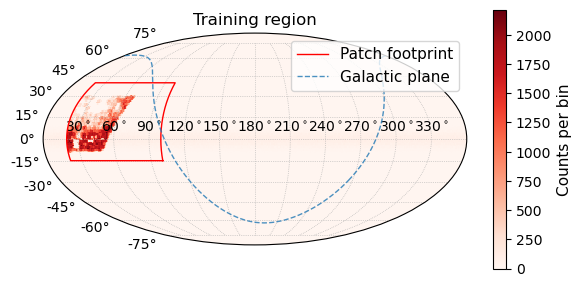

In [8]:
np.random.seed(7)
ra =A1_PATCH1['TARGET_RA'] 
dec = A1_PATCH1['TARGET_DEC'] 
ra, dec = add_plane_enhancement(ra, dec, width_deg=12, strength=3.0, frac=0.25)
#fig1 = radec_hist_density(ra, dec, bins=(360, 180))
radec_mollweide_density(ra, dec, nlon=360, nlat=180)


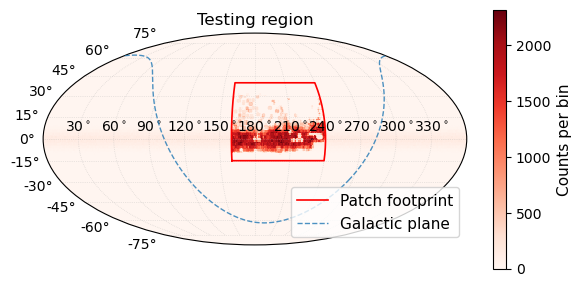

In [9]:
np.random.seed(7)
ra =A1_PATCH2['TARGET_RA'] 
dec = A1_PATCH2['TARGET_DEC'] 
ra, dec = add_plane_enhancement(ra, dec, width_deg=12, strength=3.0, frac=0.25)

#fig1 = radec_hist_density(ra, dec, bins=(360, 180))
fig2 = radec_mollweide_density_testing(ra, dec, nlon=360, nlat=180)

## 4. Build photometric features and split the data
The conditioning vector contains 23 magnitudes, colours, morphology, inverse-variance, and PSF-depth features.


In [10]:
# Milky-Way transmission corrections
trans_patch1 = transmission(A1_PATCH1["EBV"])
trans_patch2 = transmission(A1_PATCH2["EBV"])

# Extinction-corrected magnitudes
m_g_PATCH1 = 22.5 - 2.5 * np.log10(A1_PATCH1["FLUX_G"] / trans_patch1[0])
m_r_PATCH1 = 22.5 - 2.5 * np.log10(A1_PATCH1["FLUX_R"] / trans_patch1[1])
m_z_PATCH1 = 22.5 - 2.5 * np.log10(A1_PATCH1["FLUX_Z"] / trans_patch1[2])
m_w1_PATCH1 = 22.5 - 2.5 * np.log10(A1_PATCH1["FLUX_W1"] / trans_patch1[3])
m_w2_PATCH1 = 22.5 - 2.5 * np.log10(A1_PATCH1["FLUX_W2"] / trans_patch1[4])
m_i_PATCH1 = 22.5 - 2.5 * np.log10(
    A1_PATCH1["FLUX_I"] / A1_PATCH1["MW_TRANSMISSION_I"]
)

m_g_PATCH2 = 22.5 - 2.5 * np.log10(A1_PATCH2["FLUX_G"] / trans_patch2[0])
m_r_PATCH2 = 22.5 - 2.5 * np.log10(A1_PATCH2["FLUX_R"] / trans_patch2[1])
m_z_PATCH2 = 22.5 - 2.5 * np.log10(A1_PATCH2["FLUX_Z"] / trans_patch2[2])
m_w1_PATCH2 = 22.5 - 2.5 * np.log10(A1_PATCH2["FLUX_W1"] / trans_patch2[3])
m_w2_PATCH2 = 22.5 - 2.5 * np.log10(A1_PATCH2["FLUX_W2"] / trans_patch2[4])
m_i_PATCH2 = 22.5 - 2.5 * np.log10(
    A1_PATCH2["FLUX_I"] / A1_PATCH2["MW_TRANSMISSION_I"]
)


In [11]:
# Feature order used by the NF (23 conditioning variables).
FEATURE_NAMES = [
    "g", "r", "i", "z", "W1", "W2",
    "g-r", "r-i", "i-z", "z-W1", "W1-W2",
    "SHAPE_R", "SERSIC",
    "FLUX_IVAR_G", "FLUX_IVAR_R", "FLUX_IVAR_Z", "FLUX_IVAR_I",
    "FLUX_IVAR_W1", "FLUX_IVAR_W2",
    "PSFDEPTH_G", "PSFDEPTH_R", "PSFDEPTH_I", "PSFDEPTH_Z",
]

condition_data_PATCH1 = np.column_stack([
    m_g_PATCH1, m_r_PATCH1, m_i_PATCH1, m_z_PATCH1, m_w1_PATCH1, m_w2_PATCH1,
    m_g_PATCH1 - m_r_PATCH1,
    m_r_PATCH1 - m_i_PATCH1,
    m_i_PATCH1 - m_z_PATCH1,
    m_z_PATCH1 - m_w1_PATCH1,
    m_w1_PATCH1 - m_w2_PATCH1,
    A1_PATCH1["SHAPE_R"], A1_PATCH1["SERSIC"],
    A1_PATCH1["FLUX_IVAR_G"], A1_PATCH1["FLUX_IVAR_R"],
    A1_PATCH1["FLUX_IVAR_Z"], A1_PATCH1["FLUX_IVAR_I"],
    A1_PATCH1["FLUX_IVAR_W1"], A1_PATCH1["FLUX_IVAR_W2"],
    A1_PATCH1["PSFDEPTH_G"], A1_PATCH1["PSFDEPTH_R"],
    A1_PATCH1["PSFDEPTH_I"], A1_PATCH1["PSFDEPTH_Z"],
]).astype(np.float64)

condition_data_PATCH2 = np.column_stack([
    m_g_PATCH2, m_r_PATCH2, m_i_PATCH2, m_z_PATCH2, m_w1_PATCH2, m_w2_PATCH2,
    m_g_PATCH2 - m_r_PATCH2,
    m_r_PATCH2 - m_i_PATCH2,
    m_i_PATCH2 - m_z_PATCH2,
    m_z_PATCH2 - m_w1_PATCH2,
    m_w1_PATCH2 - m_w2_PATCH2,
    A1_PATCH2["SHAPE_R"], A1_PATCH2["SERSIC"],
    A1_PATCH2["FLUX_IVAR_G"], A1_PATCH2["FLUX_IVAR_R"],
    A1_PATCH2["FLUX_IVAR_Z"], A1_PATCH2["FLUX_IVAR_I"],
    A1_PATCH2["FLUX_IVAR_W1"], A1_PATCH2["FLUX_IVAR_W2"],
    A1_PATCH2["PSFDEPTH_G"], A1_PATCH2["PSFDEPTH_R"],
    A1_PATCH2["PSFDEPTH_I"], A1_PATCH2["PSFDEPTH_Z"],
]).astype(np.float64)

assert condition_data_PATCH1.shape[1] == len(FEATURE_NAMES)
assert condition_data_PATCH2.shape[1] == len(FEATURE_NAMES)


PATCH1: 1,215,941 sources
PATCH2: 2,028,371 sources


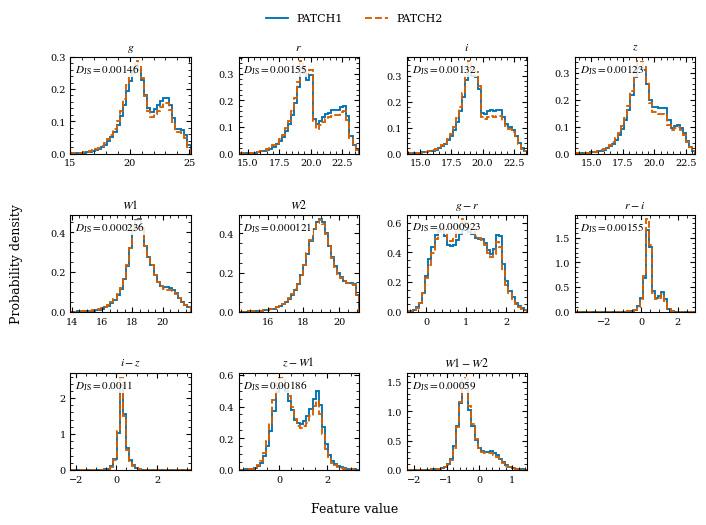

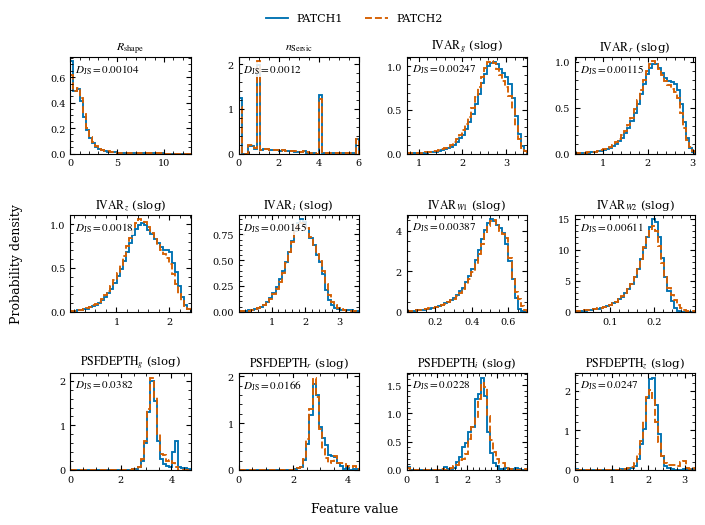


Feature comparison:
g               D_JS = 0.001457
r               D_JS = 0.001547
i               D_JS = 0.001323
z               D_JS = 0.001234
W1              D_JS = 0.000236
W2              D_JS = 0.000121
g-r             D_JS = 0.000923
r-i             D_JS = 0.001551
i-z             D_JS = 0.001103
z-W1            D_JS = 0.001860
W1-W2           D_JS = 0.000590
SHAPE_R         D_JS = 0.001044
SERSIC          D_JS = 0.001197
FLUX_IVAR_G     D_JS = 0.002467
FLUX_IVAR_R     D_JS = 0.001145
FLUX_IVAR_Z     D_JS = 0.001796
FLUX_IVAR_I     D_JS = 0.001453
FLUX_IVAR_W1    D_JS = 0.003872
FLUX_IVAR_W2    D_JS = 0.006106
PSFDEPTH_G      D_JS = 0.038192
PSFDEPTH_R      D_JS = 0.016564
PSFDEPTH_I      D_JS = 0.022778
PSFDEPTH_Z      D_JS = 0.024689


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import jensenshannon

X1 = condition_data_PATCH1
X2 = condition_data_PATCH2

assert X1.shape[1] == X2.shape[1] == len(FEATURE_NAMES)

# Remove objects with non-finite features
X1 = X1[np.all(np.isfinite(X1), axis=1)]
X2 = X2[np.all(np.isfinite(X2), axis=1)]

print(f"PATCH1: {len(X1):,} sources")
print(f"PATCH2: {len(X2):,} sources")

rng = np.random.default_rng(42)
n_max = 100000

idx1 = rng.choice(len(X1), min(n_max, len(X1)), replace=False)
idx2 = rng.choice(len(X2), min(n_max, len(X2)), replace=False)

FEATURE_LABELS = [
    r"$g$", r"$r$", r"$i$", r"$z$", r"$W1$", r"$W2$",
    r"$g-r$", r"$r-i$", r"$i-z$",
    r"$z-W1$", r"$W1-W2$",
    r"$R_{\rm shape}$", r"$n_{\rm Sersic}$",
    r"$\mathrm{IVAR}_g$", r"$\mathrm{IVAR}_r$",
    r"$\mathrm{IVAR}_z$", r"$\mathrm{IVAR}_i$",
    r"$\mathrm{IVAR}_{W1}$", r"$\mathrm{IVAR}_{W2}$",
    r"$\mathrm{PSFDEPTH}_g$",
    r"$\mathrm{PSFDEPTH}_r$",
    r"$\mathrm{PSFDEPTH}_i$",
    r"$\mathrm{PSFDEPTH}_z$",
]

def signed_log(x):
    return np.sign(x) * np.log10(1.0 + np.abs(x))

js_results = {}

def plot_feature_group(
    indices,
    filename,
    figsize=(7.1, 5.3)
):

    with plt.rc_context({
        "font.family": "serif",
        "mathtext.fontset": "stix",
        "font.size": 8,
        "axes.titlesize": 8.5,
        "axes.labelsize": 9,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 8,
        "axes.linewidth": 0.8,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }):

        fig, axes = plt.subplots(3, 4, figsize=figsize)
        axes = axes.flatten()

        for ax, j in zip(axes, indices):

            name = FEATURE_NAMES[j]

            # Subsample for plotting
            x1 = X1[:, j]
            x2 = X2[:, j]

            # Full samples for JS divergence
            x1_full = X1[:, j]
            x2_full = X2[:, j]

            is_log = (
                "FLUX_IVAR" in name
                or "PSFDEPTH" in name
            )

            if is_log:
                x1 = signed_log(x1)
                x2 = signed_log(x2)

                x1_full = signed_log(x1_full)
                x2_full = signed_log(x2_full)

            # Shared plotting range
            lo = min(
                np.percentile(x1, 0.05),
                np.percentile(x2, 0.05)
            )

            hi = max(
                np.percentile(x1, 99.9),
                np.percentile(x2, 99.9)
            )

            if hi <= lo:
                lo = min(x1.min(), x2.min())
                hi = max(x1.max(), x2.max())

            if hi <= lo:
                lo -= 0.5
                hi += 0.5

            # ----------------------------------
            # JS divergence using full samples
            # ----------------------------------
            edges_js = np.concatenate([
                [-np.inf],
                np.linspace(lo, hi, 101)[1:-1],
                [np.inf]
            ])

            h1_js, _ = np.histogram(
                x1_full, bins=edges_js
            )
            h2_js, _ = np.histogram(
                x2_full, bins=edges_js
            )

            js = jensenshannon(
                h1_js, h2_js, base=np.e
            ) ** 2

            js_results[name] = js

            # ----------------------------------
            # Histograms for visualization
            # ----------------------------------
            bins = np.linspace(lo, hi, 40)

            h1, edges = np.histogram(x1, bins=bins)
            h2, _ = np.histogram(x2, bins=bins)

            widths = np.diff(edges)

            # Normalize by entire sampled population
            d1 = h1 / (len(x1) * widths)
            d2 = h2 / (len(x2) * widths)

            ax.stairs(
                d1, edges,
                color="#0072B2",
                linewidth=1.35,
                label="PATCH1"
            )

            ax.stairs(
                d2, edges,
                color="#D55E00",
                linewidth=1.35,
                linestyle="--",
                label="PATCH2"
            )
            # JS divergence annotation
            ax.text(0.04, 0.94,rf"$D_{{\rm JS}}={js:.3g}$",transform=ax.transAxes,ha="left",va="top",fontsize=8,bbox=dict(facecolor="white",
            alpha=0.85, edgecolor="none",pad=0.5)
                   )
            title = FEATURE_LABELS[j]

            if is_log:
                title += " (slog)"

            ax.set_title(title, pad=5)

            ax.tick_params(
                which="major",
                length=3.5,
                width=0.8
            )

            ax.tick_params(
                which="minor",
                length=2,
                width=0.6
            )

            ax.minorticks_on()
            ax.set_xlim(lo, hi)

        # Hide unused panels
        for ax in axes[len(indices):]:
            ax.axis("off")

        fig.supxlabel(
            "Feature value",
            fontsize=9,
            y=0.025
        )

        fig.supylabel(
            "Probability density",
            fontsize=9,
            x=0.015
        )

        handles, labels = axes[0].get_legend_handles_labels()

        fig.legend(
            handles, labels,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.99),
            ncol=2,
            frameon=False
        )

        fig.subplots_adjust(
            left=0.10,
            right=0.98,
            bottom=0.11,
            top=0.89,
            wspace=0.40,
            hspace=0.63
        )

        fig.savefig(filename, bbox_inches="tight")
        plt.show()


# Magnitudes and colours
plot_feature_group(
    indices=list(range(11)),
    filename="PATCH_photometric_distributions.pdf"
)

# Morphology and observational features
plot_feature_group(
    indices=list(range(11, 23)),
    filename="PATCH_observational_distributions.pdf"
)

# Summary
print("\nFeature comparison:")
for name, js in js_results.items():
    print(f"{name:15s} D_JS = {js:.6f}")

In [13]:
x_data_PATCH1=A1_PATCH1['Z']
x_data_PATCH2=A1_PATCH2['Z']

In [14]:
condition_data_PATCH1, x_data_PATCH1 = shuffle(condition_data_PATCH1,x_data_PATCH1, random_state=38)
condition_data_PATCH2, x_data_PATCH2 = shuffle(condition_data_PATCH2,x_data_PATCH2, random_state=38)

In [15]:
x1_train, x2_train = train_validate_test_split( condition_data_PATCH1, x_data_PATCH1, 0 )
x1_validate, x2_validate = train_validate_test_split( condition_data_PATCH1, x_data_PATCH1, 1 )
x1_test, x2_test =condition_data_PATCH2, x_data_PATCH2

mean = np.mean(x2_train)
std = np.std(x2_train)
print(mean)
print(std)

0.6526638626304097
0.5994377217637644


### 4.1 Redshift distributions
Training and testing spectroscopic-redshift distributions, including the low-$z$ boundary near $z=0.006$.


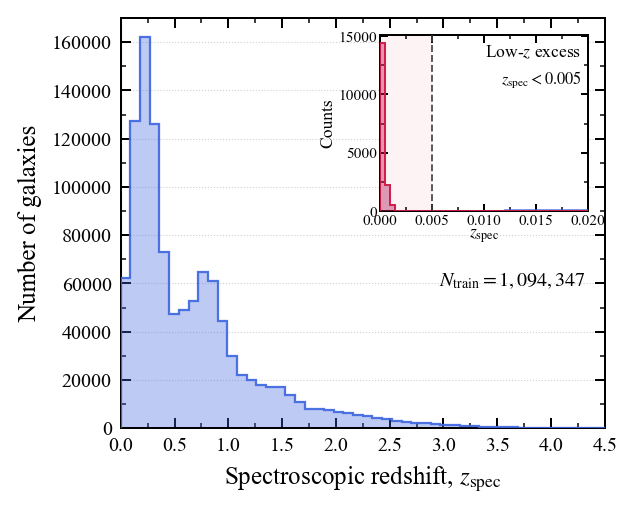

In [16]:

# ============================================================
# MNRAS-like plotting style
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "STIXGeneral",
        "DejaVu Serif",
    ],
    "mathtext.fontset": "stix",

    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    "axes.linewidth": 0.8,

    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
})
# ============================================================
# Prepare data
# ============================================================
zs_train_plot = np.asarray(x2_train, dtype=float)
# Remove NaN and infinite values
zs_train_plot = zs_train_plot[
    np.isfinite(zs_train_plot)
]
# Plotting limits
z_min = 0.0
z_max = 4.5
# Low-redshift boundary
z_cut = 0.005
# Maximum redshift displayed in inset
zoom_max = 0.020
# Total number of galaxies
n_train = len(zs_train_plot)
# Number and fraction below z = 0.006
low_mask = zs_train_plot < z_cut
n_low = np.sum(low_mask)
frac_low = n_low / n_train if n_train > 0 else np.nan

# ============================================================
# Histogram bins
# ============================================================
# Main histogram:
# Delta z = 0.02
main_bins = np.linspace(
    z_min,
    z_max,
    51,
)
# Inset:
# Delta z = 0.0005
zoom_bins = np.linspace(
    z_min,
    zoom_max,
    41,
)

# ============================================================
# Create figure
# ============================================================
fig, ax = plt.subplots(
    figsize=(3.32, 2.85),
    dpi=180,
)

# ============================================================
# Main histogram
# ============================================================
# Filled histogram
ax.hist(
    zs_train_plot,
    bins=main_bins,
    histtype="stepfilled",
    color="royalblue",
    edgecolor="royalblue",
    linewidth=0.75,
    alpha=0.35,
    zorder=2,
)
# Clear outline
ax.hist(
    zs_train_plot,
    bins=main_bins,
    histtype="step",
    color="royalblue",
    linewidth=0.90,
    alpha=0.90,
    zorder=3,
)
# Subtle indication of the region enlarged in the inset
ax.axvspan(
    z_min,
    zoom_max,
    color="crimson",
    alpha=0.035,
    linewidth=0,
    zorder=1,
)
# ============================================================
# Main-axis formatting
# ============================================================
ax.set_xlim(z_min, z_max)
ax.set_ylim(bottom=0)
ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$"
)
ax.set_ylabel(
    "Number of galaxies"
)
ax.xaxis.set_major_locator(
    MultipleLocator(0.5)
)
ax.xaxis.set_minor_locator(
    MultipleLocator(0.25)
)
ax.yaxis.set_minor_locator(
    AutoMinorLocator(2)
)
ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True,
)
# Subtle horizontal grid
ax.grid(
    axis="y",
    which="major",
    color="0.82",
    linewidth=0.45,
    linestyle=":",
    zorder=0,
)

# Total training-set size
ax.text(
    0.96,
    0.36,
    rf"$N_{{\rm train}}={n_train:,}$",
    transform=ax.transAxes,
    ha="right",
    va="center",
    fontsize=8,
)


# ============================================================
# Inset: low-redshift zoom
# ============================================================
axins = inset_axes(
    ax,
    width="43%",
    height="43%",
    loc="upper right",
    borderpad=0.75,
)

# Galaxies within the inset range
z_zoom = zs_train_plot[
    (zs_train_plot >= z_min)
    & (zs_train_plot <= zoom_max)
]

# Galaxies in the boundary-affected region
z_boundary = zs_train_plot[
    (zs_train_plot >= z_min)
    & (zs_train_plot < z_cut)
]

# ------------------------------------------------------------
# Full low-z distribution in blue
# ------------------------------------------------------------
axins.hist(
    z_zoom,
    bins=zoom_bins,
    histtype="stepfilled",
    color="royalblue",
    edgecolor="royalblue",
    linewidth=0.55,
    alpha=0.18,
    zorder=2,
)

axins.hist(
    z_zoom,
    bins=zoom_bins,
    histtype="step",
    color="royalblue",
    linewidth=0.70,
    alpha=0.75,
    zorder=3,
)
# ------------------------------------------------------------
# Highlight z < 0.006 in red
# ------------------------------------------------------------
axins.hist(
    z_boundary,
    bins=zoom_bins,
    histtype="stepfilled",
    color="crimson",
    edgecolor="crimson",
    linewidth=0.60,
    alpha=0.32,
    zorder=4,
)

axins.hist(
    z_boundary,
    bins=zoom_bins,
    histtype="step",
    color="crimson",
    linewidth=0.75,
    alpha=0.90,
    zorder=5,
)

# Light red background for the excluded region
axins.axvspan(
    z_min,
    z_cut,
    color="crimson",
    alpha=0.055,
    linewidth=0,
    zorder=1,
)

# Boundary at z = 0.006
axins.axvline(
    z_cut,
    color="0.25",
    linewidth=0.75,
    linestyle="--",
    alpha=0.90,
    zorder=6,
)
# ============================================================
# Inset formatting
# ============================================================
axins.set_xlim(z_min, zoom_max)
axins.set_ylim(bottom=0)

axins.set_xlabel(
    r"$z_{\rm spec}$",
    fontsize=7,
    labelpad=0,
)

axins.set_ylabel(
    "Counts",
    fontsize=7,
    labelpad=1,
)

# Major ticks: 0.000, 0.005, ..., 0.020
axins.xaxis.set_major_locator(
    MultipleLocator(0.005)
)

axins.xaxis.set_major_formatter(
    FormatStrFormatter("%.3f")
)

axins.xaxis.set_minor_locator(
    MultipleLocator(0.0025)
)

axins.yaxis.set_minor_locator(
    AutoMinorLocator(2)
)

axins.tick_params(
    which="major",
    direction="in",
    top=True,
    right=True,
    labelsize=6.2,
    length=3,
    pad=1,
)

axins.tick_params(
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=1.5,
)


# ============================================================
# Inset annotations
# ============================================================
# Title placed inside the inset
axins.text(
    0.97,
    0.95,
    r"Low-$z$ excess",
    transform=axins.transAxes,
    ha="right",
    va="top",
    fontsize=7.0,
)
# Description of highlighted region
axins.text(
    0.97,
    0.80,
    r"$z_{\rm spec}<0.005$",
    transform=axins.transAxes,
    ha="right",
    va="top",
    fontsize=6.5,
    color="black",
)


# ============================================================
# Final layout
# ============================================================
fig.subplots_adjust(
    left=0.17,
    right=0.98,
    bottom=0.18,
    top=0.98,
)


# ============================================================
# Save
# ============================================================
fig.savefig(
    "DESI_training_redshift_distribution_inset.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "DESI_training_redshift_distribution_inset.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

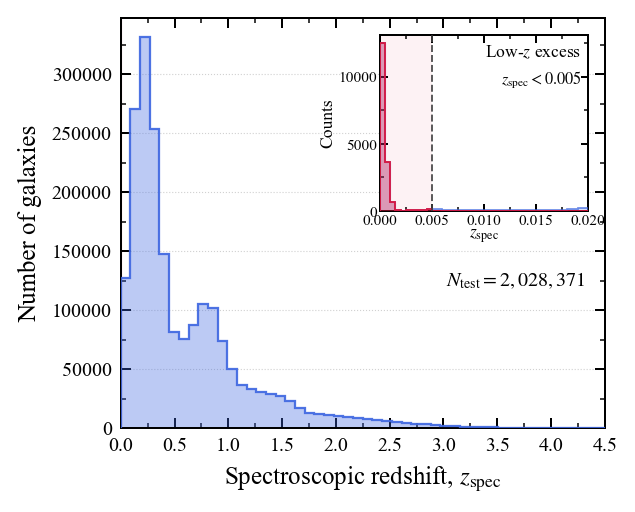

In [17]:

# ============================================================
# MNRAS-like plotting style
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "STIXGeneral",
        "DejaVu Serif",
    ],
    "mathtext.fontset": "stix",

    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    "axes.linewidth": 0.8,

    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
})


# ============================================================
# Prepare data
# ============================================================
zs_train_plot = np.asarray(x2_test, dtype=float)

# Remove NaN and infinite values
zs_train_plot = zs_train_plot[
    np.isfinite(zs_train_plot)
]

# Plotting limits
z_min = 0.0
z_max = 4.5

# Low-redshift boundary
z_cut = 0.005

# Maximum redshift displayed in inset
zoom_max = 0.020

# Total number of galaxies
n_train = len(zs_train_plot)

# Number and fraction below z = 0.006
low_mask = zs_train_plot < z_cut

n_low = np.sum(low_mask)
frac_low = n_low / n_train if n_train > 0 else np.nan


# ============================================================
# Histogram bins
# ============================================================

# Main histogram:
# Delta z = 0.02
main_bins = np.linspace(
    z_min,
    z_max,
    51,
)

# Inset:
# Delta z = 0.0005
zoom_bins = np.linspace(
    z_min,
    zoom_max,
    41,
)


# ============================================================
# Create figure
# ============================================================
fig, ax = plt.subplots(
    figsize=(3.32, 2.85),
    dpi=180,
)


# ============================================================
# Main histogram
# ============================================================

# Filled histogram
ax.hist(
    zs_train_plot,
    bins=main_bins,
    histtype="stepfilled",
    color="royalblue",
    edgecolor="royalblue",
    linewidth=0.75,
    alpha=0.35,
    zorder=2,
)

# Clear outline
ax.hist(
    zs_train_plot,
    bins=main_bins,
    histtype="step",
    color="royalblue",
    linewidth=0.90,
    alpha=0.90,
    zorder=3,
)

# Subtle indication of the region enlarged in the inset
ax.axvspan(
    z_min,
    zoom_max,
    color="crimson",
    alpha=0.035,
    linewidth=0,
    zorder=1,
)


# ============================================================
# Main-axis formatting
# ============================================================
ax.set_xlim(z_min, z_max)
ax.set_ylim(bottom=0)

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$"
)

ax.set_ylabel(
    "Number of galaxies"
)

ax.xaxis.set_major_locator(
    MultipleLocator(0.5)
)

ax.xaxis.set_minor_locator(
    MultipleLocator(0.25)
)

ax.yaxis.set_minor_locator(
    AutoMinorLocator(2)
)

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True,
)

# Subtle horizontal grid
ax.grid(
    axis="y",
    which="major",
    color="0.82",
    linewidth=0.45,
    linestyle=":",
    zorder=0,
)

# Total training-set size
ax.text(
    0.96,
    0.36,
    rf"$N_{{\rm test}}={n_train:,}$",
    transform=ax.transAxes,
    ha="right",
    va="center",
    fontsize=8,
)


# ============================================================
# Inset: low-redshift zoom
# ============================================================
axins = inset_axes(
    ax,
    width="43%",
    height="43%",
    loc="upper right",
    borderpad=0.75,
)

# Galaxies within the inset range
z_zoom = zs_train_plot[
    (zs_train_plot >= z_min)
    & (zs_train_plot <= zoom_max)
]

# Galaxies in the boundary-affected region
z_boundary = zs_train_plot[
    (zs_train_plot >= z_min)
    & (zs_train_plot < z_cut)
]


# ------------------------------------------------------------
# Full low-z distribution in blue
# ------------------------------------------------------------
axins.hist(
    z_zoom,
    bins=zoom_bins,
    histtype="stepfilled",
    color="royalblue",
    edgecolor="royalblue",
    linewidth=0.55,
    alpha=0.18,
    zorder=2,
)

axins.hist(
    z_zoom,
    bins=zoom_bins,
    histtype="step",
    color="royalblue",
    linewidth=0.70,
    alpha=0.75,
    zorder=3,
)


# ------------------------------------------------------------
# Highlight z < 0.006 in red
# ------------------------------------------------------------
axins.hist(
    z_boundary,
    bins=zoom_bins,
    histtype="stepfilled",
    color="crimson",
    edgecolor="crimson",
    linewidth=0.60,
    alpha=0.32,
    zorder=4,
)

axins.hist(
    z_boundary,
    bins=zoom_bins,
    histtype="step",
    color="crimson",
    linewidth=0.75,
    alpha=0.90,
    zorder=5,
)

# Light red background for the excluded region
axins.axvspan(
    z_min,
    z_cut,
    color="crimson",
    alpha=0.055,
    linewidth=0,
    zorder=1,
)

# Boundary at z = 0.006
axins.axvline(
    z_cut,
    color="0.25",
    linewidth=0.75,
    linestyle="--",
    alpha=0.90,
    zorder=6,
)


# ============================================================
# Inset formatting
# ============================================================
axins.set_xlim(z_min, zoom_max)
axins.set_ylim(bottom=0)

axins.set_xlabel(
    r"$z_{\rm spec}$",
    fontsize=7,
    labelpad=0,
)

axins.set_ylabel(
    "Counts",
    fontsize=7,
    labelpad=1,
)

# Major ticks: 0.000, 0.005, ..., 0.020
axins.xaxis.set_major_locator(
    MultipleLocator(0.005)
)

axins.xaxis.set_major_formatter(
    FormatStrFormatter("%.3f")
)

axins.xaxis.set_minor_locator(
    MultipleLocator(0.0025)
)

axins.yaxis.set_minor_locator(
    AutoMinorLocator(2)
)

axins.tick_params(
    which="major",
    direction="in",
    top=True,
    right=True,
    labelsize=6.2,
    length=3,
    pad=1,
)

axins.tick_params(
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=1.5,
)


# ============================================================
# Inset annotations
# ============================================================

# Title placed inside the inset
axins.text(
    0.97,
    0.95,
    r"Low-$z$ excess",
    transform=axins.transAxes,
    ha="right",
    va="top",
    fontsize=7.0,
)

# Description of highlighted region
axins.text(
    0.97,
    0.80,
    r"$z_{\rm spec}<0.005$",
    transform=axins.transAxes,
    ha="right",
    va="top",
    fontsize=6.5,
    color="black",
)


# ============================================================
# Final layout
# ============================================================
fig.subplots_adjust(
    left=0.17,
    right=0.98,
    bottom=0.18,
    top=0.98,
)


# ============================================================
# Save
# ============================================================
fig.savefig(
    "DESI_testing_redshift_distribution_inset.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "DESI_testing_redshift_distribution_inset.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 4.2 Standardization and PyTorch tensors
Fit scalers only on the training sample, then transform validation/testing samples.


In [18]:
scaler_condition = StandardScaler()
x1_train = scaler_condition.fit_transform(x1_train) 
x1_validate = scaler_condition.transform(x1_validate)  
x1_test = scaler_condition.transform(x1_test)

scaler_x = StandardScaler()
x2_train = scaler_x.fit_transform(x2_train.reshape(-1, 1))
x2_validate = scaler_x.transform(x2_validate.reshape(-1, 1))
x2_test = scaler_x.transform(x2_test.reshape(-1, 1))
    
x1_train = torch.tensor(x1_train, dtype=torch.float32).to(device)
x1_validate = torch.tensor(x1_validate, dtype=torch.float32).to(device)
x1_test = torch.tensor(x1_test, dtype=torch.float32).to(device)

x2_train = torch.tensor(x2_train, dtype=torch.float32).to(device)
x2_validate = torch.tensor(x2_validate, dtype=torch.float32).to(device)
x2_test = torch.tensor(x2_test, dtype=torch.float32).to(device)

print("x1_train.shape:", x1_train.shape)
print("x2_train.shape:", x2_train.shape)
print("x1_validate.shape:", x1_validate.shape)
print("x2_validate.shape:", x2_validate.shape)

x1_train.shape: torch.Size([1094347, 23])
x2_train.shape: torch.Size([1094347, 1])
x1_validate.shape: torch.Size([121594, 23])
x2_validate.shape: torch.Size([121594, 1])


## 5. Normalizing Flow
Train the conditional spline flow or load a selected checkpoint, then sample the posterior $p(z\mid\mathbf{x})$ and derive point estimators.


In [520]:
dist_x2_given_x1,nll_train1,nll_valid1 = model_training(x1_train, x2_train, x1_validate, x2_validate,output_model="normalizing_flow_retrain1.pt")

000 	00000/04275 	0.01 	2.205078 	2.019839 	1.00e-03
000 	00100/04275 	0.09 	0.435156 	0.410519 	1.00e-03
000 	00200/04275 	0.17 	0.084923 	0.069190 	1.00e-03
000 	00300/04275 	0.26 	-0.072422 	-0.080465 	1.00e-03
000 	00400/04275 	0.34 	-0.171196 	-0.176083 	1.00e-03
000 	00500/04275 	0.42 	-0.232796 	-0.242185 	1.00e-03
000 	00600/04275 	0.50 	-0.287456 	-0.293333 	1.00e-03
000 	00700/04275 	0.58 	-0.329905 	-0.334702 	1.00e-03
000 	00800/04275 	0.67 	-0.369339 	-0.370699 	1.00e-03
000 	00900/04275 	0.75 	-0.400669 	-0.401282 	1.00e-03
000 	01000/04275 	0.83 	-0.427720 	-0.427698 	1.00e-03
000 	01100/04275 	0.92 	-0.450303 	-0.450324 	1.00e-03
000 	01200/04275 	1.00 	-0.471876 	-0.471049 	1.00e-03
000 	01300/04275 	1.09 	-0.491477 	-0.489637 	1.00e-03
000 	01400/04275 	1.17 	-0.508169 	-0.506361 	1.00e-03
000 	01500/04275 	1.25 	-0.522780 	-0.521596 	1.00e-03
000 	01600/04275 	1.33 	-0.536896 	-0.535235 	1.00e-03
000 	01700/04275 	1.41 	-0.549634 	-0.548233 	1.00e-03
000 	01800/04275

003 	02000/04275 	12.41 	-0.970897 	-0.968221 	1.00e-03
003 	02100/04275 	12.49 	-0.971667 	-0.968735 	1.00e-03
003 	02200/04275 	12.57 	-0.972756 	-0.969358 	1.00e-03
003 	02300/04275 	12.66 	-0.971057 	-0.968516 	1.00e-03
003 	02400/04275 	12.74 	-0.970949 	-0.968729 	1.00e-03
003 	02500/04275 	12.83 	-0.971071 	-0.968974 	1.00e-03
003 	02600/04275 	12.91 	-0.971229 	-0.969190 	1.00e-03
003 	02700/04275 	12.99 	-0.971618 	-0.969516 	1.00e-03
003 	02800/04275 	13.08 	-0.971674 	-0.969737 	1.00e-03
003 	02900/04275 	13.16 	-0.972361 	-0.970291 	1.00e-03
003 	03000/04275 	13.25 	-0.973016 	-0.970803 	1.00e-03
003 	03100/04275 	13.33 	-0.973205 	-0.971010 	1.00e-03
003 	03200/04275 	13.41 	-0.973505 	-0.971327 	1.00e-03
003 	03300/04275 	13.49 	-0.974305 	-0.971665 	1.00e-03
003 	03400/04275 	13.58 	-0.974663 	-0.972164 	1.00e-03
003 	03500/04275 	13.66 	-0.974571 	-0.972019 	1.00e-03
003 	03600/04275 	13.75 	-0.974796 	-0.972588 	1.00e-03
003 	03700/04275 	13.83 	-0.974542 	-0.972897 	1

009 	01600/04275 	33.76 	-1.037556 	-1.030936 	1.00e-03
009 	01700/04275 	33.84 	-1.037303 	-1.031458 	1.00e-03
009 	01800/04275 	33.93 	-1.037713 	-1.031533 	1.00e-03
009 	01900/04275 	34.01 	-1.037115 	-1.031659 	1.00e-03
009 	02000/04275 	34.09 	-1.037306 	-1.031750 	1.00e-03
009 	02100/04275 	34.18 	-1.036830 	-1.031515 	1.00e-03
009 	02200/04275 	34.26 	-1.036932 	-1.031744 	1.00e-03
009 	02300/04275 	34.35 	-1.037000 	-1.031810 	1.00e-03
009 	02400/04275 	34.44 	-1.037181 	-1.031692 	1.00e-03
009 	02500/04275 	34.52 	-1.037219 	-1.031944 	1.00e-03
009 	02600/04275 	34.60 	-1.036655 	-1.031838 	1.00e-03
009 	02700/04275 	34.69 	-1.036428 	-1.032091 	1.00e-03
009 	02800/04275 	34.77 	-1.036212 	-1.032033 	1.00e-03
009 	02900/04275 	34.85 	-1.036182 	-1.032185 	1.00e-03
009 	03000/04275 	34.94 	-1.035114 	-1.031416 	1.00e-03
009 	03100/04275 	35.02 	-1.035204 	-1.031511 	1.00e-03
009 	03200/04275 	35.10 	-1.034899 	-1.031670 	1.00e-03
009 	03300/04275 	35.19 	-1.035398 	-1.031865 	1

012 	03400/04275 	46.09 	-1.047576 	-1.046427 	1.00e-03
012 	03500/04275 	46.18 	-1.047767 	-1.046499 	1.00e-03
012 	03600/04275 	46.26 	-1.047951 	-1.046446 	1.00e-03
012 	03700/04275 	46.34 	-1.048167 	-1.046427 	1.00e-03
012 	03800/04275 	46.43 	-1.048347 	-1.046562 	1.00e-03
012 	03900/04275 	46.51 	-1.048528 	-1.046635 	1.00e-03
012 	04000/04275 	46.59 	-1.049269 	-1.046821 	1.00e-03
012 	04100/04275 	46.68 	-1.049488 	-1.047005 	1.00e-03
012 	04200/04275 	46.76 	-1.049735 	-1.047136 	1.00e-03
013 	00000/04275 	46.82 	-0.908942 	-1.059541 	1.00e-03
013 	00100/04275 	46.90 	-1.064833 	-1.047811 	1.00e-03
013 	00200/04275 	46.99 	-1.060076 	-1.044927 	1.00e-03
013 	00300/04275 	47.07 	-1.058844 	-1.050628 	1.00e-03
013 	00400/04275 	47.16 	-1.058838 	-1.052206 	1.00e-03
013 	00500/04275 	47.24 	-1.056710 	-1.051100 	1.00e-03
013 	00600/04275 	47.33 	-1.056684 	-1.050314 	1.00e-03
013 	00700/04275 	47.41 	-1.056033 	-1.049239 	1.00e-03
013 	00800/04275 	47.50 	-1.055967 	-1.048998 	1

021 	00500/04275 	75.84 	-1.074452 	-1.067234 	1.00e-03
021 	00600/04275 	75.92 	-1.070757 	-1.065468 	1.00e-03
021 	00700/04275 	76.00 	-1.070298 	-1.065329 	1.00e-03
021 	00800/04275 	76.08 	-1.071774 	-1.065798 	1.00e-03
021 	00900/04275 	76.17 	-1.071695 	-1.066260 	1.00e-03
021 	01000/04275 	76.25 	-1.071166 	-1.065841 	1.00e-03
021 	01100/04275 	76.34 	-1.070104 	-1.065136 	1.00e-03
021 	01200/04275 	76.42 	-1.068979 	-1.065130 	1.00e-03
021 	01300/04275 	76.51 	-1.068886 	-1.064400 	1.00e-03
021 	01400/04275 	76.59 	-1.068546 	-1.064290 	1.00e-03
021 	01500/04275 	76.67 	-1.068400 	-1.064534 	1.00e-03
021 	01600/04275 	76.75 	-1.068663 	-1.064298 	1.00e-03
021 	01700/04275 	76.83 	-1.068334 	-1.063997 	1.00e-03
021 	01800/04275 	76.91 	-1.068095 	-1.064107 	1.00e-03
021 	01900/04275 	77.00 	-1.067884 	-1.064046 	1.00e-03
021 	02000/04275 	77.08 	-1.067514 	-1.063904 	1.00e-03
021 	02100/04275 	77.16 	-1.068119 	-1.063865 	1.00e-03
021 	02200/04275 	77.25 	-1.068124 	-1.063934 	1

...

061 	01900/04275 	219.77 	-1.152512 	-1.144889 	1.00e-04
061 	02000/04275 	219.85 	-1.152303 	-1.144801 	1.00e-04
061 	02100/04275 	219.94 	-1.152008 	-1.144837 	1.00e-04
061 	02200/04275 	220.02 	-1.151703 	-1.144985 	1.00e-04
061 	02300/04275 	220.10 	-1.150708 	-1.145065 	1.00e-04
061 	02400/04275 	220.18 	-1.150338 	-1.145070 	1.00e-04
061 	02500/04275 	220.27 	-1.150268 	-1.144928 	1.00e-04
061 	02600/04275 	220.35 	-1.150458 	-1.144948 	1.00e-04
061 	02700/04275 	220.44 	-1.150649 	-1.145063 	1.00e-04
061 	02800/04275 	220.52 	-1.151080 	-1.145173 	1.00e-04
061 	02900/04275 	220.60 	-1.151214 	-1.145342 	1.00e-04
061 	03000/04275 	220.68 	-1.151723 	-1.145280 	1.00e-04
061 	03100/04275 	220.76 	-1.151293 	-1.145328 	1.00e-04
061 	03200/04275 	220.84 	-1.151623 	-1.145338 	1.00e-04
061 	03300/04275 	220.93 	-1.151555 	-1.145183 	1.00e-04
061 	03400/04275 	221.01 	-1.151132 	-1.145155 	1.00e-04
061 	03500/04275 	221.09 	-1.151300 	-1.145220 	1.00e-04
061 	03600/04275 	221.17 	-1.15

064 	03400/04275 	231.72 	-1.151664 	-1.145099 	1.00e-04
064 	03500/04275 	231.81 	-1.151532 	-1.145112 	1.00e-04
064 	03600/04275 	231.89 	-1.151394 	-1.145058 	1.00e-04
064 	03700/04275 	231.97 	-1.151731 	-1.145107 	1.00e-04
064 	03800/04275 	232.06 	-1.152078 	-1.145163 	1.00e-04
064 	03900/04275 	232.14 	-1.151740 	-1.145116 	1.00e-04
064 	04000/04275 	232.22 	-1.151652 	-1.145035 	1.00e-04
064 	04100/04275 	232.31 	-1.151747 	-1.145019 	1.00e-04
064 	04200/04275 	232.39 	-1.152126 	-1.145062 	1.00e-04
065 	00000/04275 	232.45 	-1.148010 	-1.141623 	1.00e-04
065 	00100/04275 	232.53 	-1.136138 	-1.146686 	1.00e-04
065 	00200/04275 	232.61 	-1.142078 	-1.146357 	1.00e-04
065 	00300/04275 	232.70 	-1.143861 	-1.146417 	1.00e-04
065 	00400/04275 	232.78 	-1.147523 	-1.146524 	1.00e-04
065 	00500/04275 	232.86 	-1.149837 	-1.146555 	1.00e-04
065 	00600/04275 	232.94 	-1.150314 	-1.146759 	1.00e-04
065 	00700/04275 	233.03 	-1.151506 	-1.146289 	1.00e-04
065 	00800/04275 	233.11 	-1.15

068 	00600/04275 	243.68 	-1.152305 	-1.145258 	1.00e-04
068 	00700/04275 	243.76 	-1.153726 	-1.145479 	1.00e-04
068 	00800/04275 	243.85 	-1.154238 	-1.145370 	1.00e-04
068 	00900/04275 	243.93 	-1.155339 	-1.145484 	1.00e-04
068 	01000/04275 	244.02 	-1.155068 	-1.145757 	1.00e-04
068 	01100/04275 	244.10 	-1.156661 	-1.145967 	1.00e-04
068 	01200/04275 	244.18 	-1.158044 	-1.146030 	1.00e-04
068 	01300/04275 	244.26 	-1.156814 	-1.145750 	1.00e-04
068 	01400/04275 	244.35 	-1.156836 	-1.145779 	1.00e-04
068 	01500/04275 	244.43 	-1.155650 	-1.145758 	1.00e-04
068 	01600/04275 	244.52 	-1.156303 	-1.145921 	1.00e-04
068 	01700/04275 	244.60 	-1.155095 	-1.145818 	1.00e-04
068 	01800/04275 	244.68 	-1.155157 	-1.145948 	1.00e-04
068 	01900/04275 	244.76 	-1.154688 	-1.146069 	1.00e-04
068 	02000/04275 	244.84 	-1.153753 	-1.146143 	1.00e-04
068 	02100/04275 	244.92 	-1.153149 	-1.146323 	1.00e-04
068 	02200/04275 	245.01 	-1.152560 	-1.146258 	1.00e-04
068 	02300/04275 	245.09 	-1.15

071 	02100/04275 	255.65 	-1.152015 	-1.145038 	1.00e-04
071 	02200/04275 	255.73 	-1.151726 	-1.144991 	1.00e-04
071 	02300/04275 	255.81 	-1.152351 	-1.144964 	1.00e-04
071 	02400/04275 	255.89 	-1.151772 	-1.145006 	1.00e-04
071 	02500/04275 	255.98 	-1.151876 	-1.145066 	1.00e-04
071 	02600/04275 	256.07 	-1.152328 	-1.145235 	1.00e-04
071 	02700/04275 	256.15 	-1.152397 	-1.145253 	1.00e-04
071 	02800/04275 	256.23 	-1.152599 	-1.145185 	1.00e-04
071 	02900/04275 	256.32 	-1.151922 	-1.145136 	1.00e-04
071 	03000/04275 	256.40 	-1.152173 	-1.145170 	1.00e-04
071 	03100/04275 	256.48 	-1.151926 	-1.145248 	1.00e-04
071 	03200/04275 	256.56 	-1.152247 	-1.145256 	1.00e-04
071 	03300/04275 	256.64 	-1.152032 	-1.145324 	1.00e-04
071 	03400/04275 	256.73 	-1.152285 	-1.145367 	1.00e-04
071 	03500/04275 	256.81 	-1.151975 	-1.145294 	1.00e-04
071 	03600/04275 	256.89 	-1.151933 	-1.145325 	1.00e-04
071 	03700/04275 	256.97 	-1.152171 	-1.145418 	1.00e-04
071 	03800/04275 	257.05 	-1.15

074 	03600/04275 	267.62 	-1.151491 	-1.144999 	1.00e-04
074 	03700/04275 	267.70 	-1.151437 	-1.145132 	1.00e-04
074 	03800/04275 	267.79 	-1.152065 	-1.145135 	1.00e-04
074 	03900/04275 	267.87 	-1.151979 	-1.145209 	1.00e-04
074 	04000/04275 	267.96 	-1.152103 	-1.145237 	1.00e-04
074 	04100/04275 	268.04 	-1.151999 	-1.145285 	1.00e-04
074 	04200/04275 	268.12 	-1.151970 	-1.145225 	1.00e-04
Final model saved to normalizing_flow_retrain1.pt


In [19]:
#reload the trained model, you can use the former training model or the models I uploaded in github.For 'spec-z>1'. please upload model with 'high'.
dist_x2_given_x1, x2_transform = load_model(
    "normalizing_flow_retrain2.pt"
)

In [20]:
model_paths = [
    "normalizing_flow_retrain1.pt",
    "normalizing_flow_retrain2.pt",
    "normalizing_flow_retrain3.pt",
    "normalizing_flow_retrain4.pt",
    "normalizing_flow_retrain5.pt",
]

nll_train = []
nll_validate=[]
for path in model_paths:
    nll = evaluate_saved_nll(
        path,
        x1_train,
        x2_train
    )
    nll_train.append(nll)
    print(path, nll)

print(
    "Training NLL:",
    np.mean(nll_train),
    "+/-",
    np.std(nll_train, ddof=1)
)
for path in model_paths:
    nll = evaluate_saved_nll(
        path,
        x1_validate,
        x2_validate
    )
    nll_validate.append(nll)
    print(path, nll)

print(
    "validate NLL:",
    np.mean(nll_validate),
    "+/-",
    np.std(nll_validate, ddof=1)
)

normalizing_flow_retrain1.pt -1.1597693516935428
normalizing_flow_retrain2.pt -1.1568658123095468
normalizing_flow_retrain3.pt -1.163920287333558
normalizing_flow_retrain4.pt -1.1606370313258159
normalizing_flow_retrain5.pt -1.1082909546493538
Training NLL: -1.1498966874623633 +/- 0.02339386427419244
normalizing_flow_retrain1.pt -1.151954788290078
normalizing_flow_retrain2.pt -1.157632723320024
normalizing_flow_retrain3.pt -1.1659760987705499
normalizing_flow_retrain4.pt -1.1610732822156882
normalizing_flow_retrain5.pt -1.1072674002469283
validate NLL: -1.1487808585686536 +/- 0.023762241718753133


In [21]:
#obtain the spec-z for testing data
zs = scaler_x.inverse_transform(x2_test.detach().cpu().numpy().reshape(-1, 1)).flatten()


In [22]:
#output the testing PDFs and point estimation from NF model
x2_flow,z_maxp, z_median, z_mean, err_std, err_68halfpc= test_sample_dist( x1_test, x2_test, zs, mean, std )

## 6. Baseline models
### 6.1 Random Forest



In [22]:
def train_rf(A1_PATCH1,A1_PATCH2): 
    RA=A1_PATCH2['TARGET_RA']
    DEC=A1_PATCH2['TARGET_DEC']
    Tran_PATCH1=transmission(A1_PATCH1['EBV'])
    Tran_PATCH2=transmission(A1_PATCH2['EBV'])
    m_g_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_G']/Tran_PATCH1[0])
    m_r_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_R']/Tran_PATCH1[1])
    m_z_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_Z']/Tran_PATCH1[2])
    m_w1_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_W1']/Tran_PATCH1[3])
    m_w2_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_W2']/Tran_PATCH1[4])
    m_g_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_G']/Tran_PATCH2[0])
    m_r_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_R']/Tran_PATCH2[1])
    m_z_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_Z']/Tran_PATCH2[2])
    m_w1_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_W1']/Tran_PATCH2[3])
    m_w2_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_W2']/Tran_PATCH2[4])
    m_i_PATCH1=22.5-2.5*np.log10(A1_PATCH1['FLUX_I']/A1_PATCH1['MW_TRANSMISSION_I'])
    m_i_PATCH2=22.5-2.5*np.log10(A1_PATCH2['FLUX_I']/A1_PATCH2['MW_TRANSMISSION_I'])
    condition_data_PATCH1=np.vstack((m_g_PATCH1,m_r_PATCH1,m_i_PATCH1,m_z_PATCH1,m_w1_PATCH1,m_w2_PATCH1,m_g_PATCH1-m_r_PATCH1,m_r_PATCH1-m_i_PATCH1,m_i_PATCH1-m_z_PATCH1,m_z_PATCH1-m_w1_PATCH1,m_w1_PATCH1-m_w2_PATCH1,A1_PATCH1['SHAPE_R'],A1_PATCH1['SERSIC'],A1_PATCH1['FLUX_IVAR_G'],A1_PATCH1['FLUX_IVAR_R'],A1_PATCH1['FLUX_IVAR_Z'],A1_PATCH1['FLUX_IVAR_I'],A1_PATCH1['FLUX_IVAR_W1'],A1_PATCH1['FLUX_IVAR_W2'],A1_PATCH1['PSFDEPTH_G'],A1_PATCH1['PSFDEPTH_R'],A1_PATCH1['PSFDEPTH_I'],A1_PATCH1['PSFDEPTH_Z']),dtype=np.float64)
    condition_data_PATCH1=np.transpose(condition_data_PATCH1)
    condition_data_PATCH2=np.vstack((m_g_PATCH2,m_r_PATCH2,m_i_PATCH2,m_z_PATCH2,m_w1_PATCH2,m_w2_PATCH2,m_g_PATCH2-m_r_PATCH2,m_r_PATCH2-m_i_PATCH2,m_i_PATCH2-m_z_PATCH2,m_z_PATCH2-m_w1_PATCH2,m_w1_PATCH2-m_w2_PATCH2,A1_PATCH2['SHAPE_R'],A1_PATCH2['SERSIC'],A1_PATCH2['FLUX_IVAR_G'],A1_PATCH2['FLUX_IVAR_R'],A1_PATCH2['FLUX_IVAR_Z'],A1_PATCH2['FLUX_IVAR_I'],A1_PATCH2['FLUX_IVAR_W1'],A1_PATCH2['FLUX_IVAR_W2'],A1_PATCH2['PSFDEPTH_G'],A1_PATCH2['PSFDEPTH_R'],A1_PATCH2['PSFDEPTH_I'],A1_PATCH2['PSFDEPTH_Z']),dtype=np.float64)
    condition_data_PATCH2=np.transpose(condition_data_PATCH2)
    x_data_PATCH1=np.array(A1_PATCH1['Z'],dtype=np.float64)
    x_data_PATCH2=np.array(A1_PATCH2['Z'],dtype=np.float64)
    condition_data_PATCH1, x_data_PATCH1 = shuffle(condition_data_PATCH1,x_data_PATCH1, random_state=42)
    X_train = condition_data_PATCH1
    y_train = x_data_PATCH1
    X_test  = condition_data_PATCH2
    y_test  = x_data_PATCH2
    rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestRegressor(
        n_estimators=500,         # 先给一个稳一点的值
        max_depth=None,
        min_samples_leaf=5,       # 比默认更稳，能减少过拟合
        max_features="sqrt",      # 常用设置
        n_jobs=-1,
        random_state=42
    ))
  ])

    rf_model.fit(X_train, y_train)
    z_rf = rf_model.predict(X_test)

    return y_test,z_rf,np.array(RA),np.array(DEC)

In [23]:
RF= train_rf(A1_PATCH1,A1_PATCH2)

### 6.2 Quantile Random Forest
QRF predicts 99 quantiles from 0.01 to 0.99, plus the posterior median and 16th--84th percentile width.


In [64]:
def build_qrf_features(cat):
    """Construct the 23 QRF input features."""
    trans = transmission(cat["EBV"])

    g  = 22.5 - 2.5 * np.log10(cat["FLUX_G"]  / trans[0])
    r  = 22.5 - 2.5 * np.log10(cat["FLUX_R"]  / trans[1])
    z  = 22.5 - 2.5 * np.log10(cat["FLUX_Z"]  / trans[2])
    w1 = 22.5 - 2.5 * np.log10(cat["FLUX_W1"] / trans[3])
    w2 = 22.5 - 2.5 * np.log10(cat["FLUX_W2"] / trans[4])
    i  = 22.5 - 2.5 * np.log10(
        cat["FLUX_I"] / cat["MW_TRANSMISSION_I"]
    )

    return np.column_stack([
        g, r, i, z, w1, w2,
        g-r, r-i, i-z, z-w1, w1-w2,
        cat["SHAPE_R"], cat["SERSIC"],
        cat["FLUX_IVAR_G"], cat["FLUX_IVAR_R"],
        cat["FLUX_IVAR_Z"], cat["FLUX_IVAR_I"],
        cat["FLUX_IVAR_W1"], cat["FLUX_IVAR_W2"],
        cat["PSFDEPTH_G"], cat["PSFDEPTH_R"],
        cat["PSFDEPTH_I"], cat["PSFDEPTH_Z"],
    ]).astype(np.float32)


def stack_qrf_quantile_histograms(quantiles, z_edges):
    """Stack individual QRF quantile distributions."""
    stacked = np.zeros(len(z_edges) - 1)

    for q in quantiles:
        hist, _ = np.histogram(q, bins=z_edges)
        if hist.sum() > 0:
            stacked += hist / hist.sum()

    return stacked


def train_qrf(train_cat, test_cat):
    """Train QRF and reconstruct the full-sample N(z)."""

    X_train = build_qrf_features(train_cat)
    X_test = build_qrf_features(test_cat)

    y_train = np.asarray(train_cat["Z"], dtype=np.float32)
    y_test = np.asarray(test_cat["Z"], dtype=np.float32)

    X_train, y_train = shuffle(
        X_train, y_train, random_state=42
    )

    qrf = RandomForestQuantileRegressor(
        n_estimators=500,
        max_depth=20,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1,
    )
    qrf.fit(X_train, y_train)

    # Quantile PDFs
    quantiles = np.linspace(0.01, 0.99, 99).tolist()
    y_pred_q = qrf.predict(
        X_test, quantiles=quantiles
    ).astype(np.float32)

    # Point estimates
    z_pred = qrf.predict(X_test, quantiles=0.5).reshape(-1)
    z_lo, z_hi = qrf.predict(
        X_test, quantiles=[0.16, 0.84]
    ).T
    z_err = 0.5 * (z_hi - z_lo)

    # N(z)
    z_edges = np.linspace(0.0, 4.5, 200)
    z_centres = 0.5 * (z_edges[:-1] + z_edges[1:])

    nspec_qrf, _ = np.histogram(y_test, bins=z_edges)
    nmedian_qrf, _ = np.histogram(z_pred, bins=z_edges)
    npred_qrf = stack_qrf_quantile_histograms(
        y_pred_q, z_edges
    )

    return (
        y_test,
        z_pred,
        z_err,
        np.asarray(test_cat["TARGET_RA"]),
        np.asarray(test_cat["TARGET_DEC"]),
        z_centres,
        nspec_qrf,
        npred_qrf,
        nmedian_qrf,
        y_pred_q,
    )

In [7]:
QRF = train_qrf(A1_PATCH1, A1_PATCH2)


In [9]:
y_pred_q = QRF[9]  # dense 0.01--0.99 quantile predictions


In [ ]:
#### Optional persistence of QRF predictions
These cells save/reload the dense quantiles.


In [ ]:
np.save(
        "QRF_all_PDFs.npy",
        y_pred_q
    )
np.save(
        "zspec_QRF.npy",
        QRF[0]
    )

In [62]:

zspec_qrf = np.load(
    "zspec_QRF.npy",
    allow_pickle=False,
)
qrf_pdfs = np.load(
    "QRF_all_PDFs.npy",
    allow_pickle=False,
)
y_pred_q=qrf_pdfs

In [65]:
z_edges = np.linspace(0.0, 4.5, 200)
z_centres = 0.5 * (z_edges[:-1] + z_edges[1:])

npred_qrf = stack_qrf_quantile_histograms(
        y_pred_q, z_edges)

In [66]:
qrf_median=np.median(qrf_pdfs,axis=1)

## 7. Point-estimate comparison
Evaluate point metrics and compare the $z_{\rm spec}$--$z_{\rm phot}$ distributions for NF, QRF, and RF.



Number of galaxies:  1,880,915
Median bias:         +0.001665
Mean bias:           +0.021829
sigma_NMAD:          0.027134
Number of outliers:  89,893
Outlier fraction:    4.779%


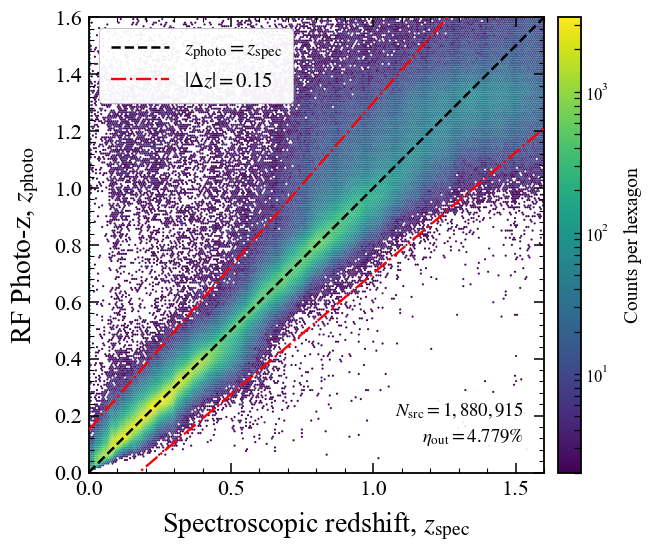

In [24]:
# ============================================================
# Large MNRAS-style figure
# Suitable for a double-column figure
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",

    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 15,

    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
})
# ============================================================
# Input data
# ============================================================
z_spec = RF[0]
z_median_RF = RF[1]
outlier_threshold=0.15
if z_spec.size != z_median_RF.size:
    raise ValueError(
        f"Array-length mismatch: "
        f"z_spec={z_spec.size:,}, "
        f"z_median={z_median_RF.size:,}"
    )

# ============================================================
# Analysis sample
# Used to calculate N_gal and the outlier fraction
# ============================================================
zspec_min = 0.0
zspec_max = 1.6

analysis_mask = (
    np.isfinite(z_spec)
    & np.isfinite(z_median_RF)
    & (z_spec >= zspec_min)
    & (z_spec <= zspec_max)
)

z_spec_analysis = z_spec[analysis_mask]
z_median_analysis = z_median_RF[analysis_mask]

# ============================================================
# Catastrophic-outlier definition
# ============================================================
delta_z_normalized = (
    z_median_analysis - z_spec_analysis
) / (1.0 + z_spec_analysis)

# Bias: median normalized residual
bias = np.median(delta_z_normalized)

# Mean bias, optional diagnostic
mean_bias = np.mean(delta_z_normalized)

# Normalized median absolute deviation
sigma_nmad = 1.4826 * np.median(
    np.abs(delta_z_normalized - bias)
)

# Catastrophic outliers
outlier_mask = (
    np.abs(delta_z_normalized) > outlier_threshold
)

n_gal = z_spec_analysis.size
n_outlier = np.count_nonzero(outlier_mask)
outlier_fraction = n_outlier / n_gal

print(f"Number of galaxies:  {n_gal:,}")
print(f"Median bias:         {bias:+.6f}")
print(f"Mean bias:           {mean_bias:+.6f}")
print(f"sigma_NMAD:          {sigma_nmad:.6f}")
print(f"Number of outliers:  {n_outlier:,}")
print(f"Outlier fraction:    {100 * outlier_fraction:.3f}%")
# ============================================================
# Plot range
#
# The plot range does not affect the outlier-fraction calculation.
# ============================================================
x_min, x_max = 0.0, 1.6
y_min, y_max = 0.0, 1.6

plot_mask = (
    (z_spec_analysis >= x_min)
    & (z_spec_analysis <= x_max)
    & (z_median_analysis >= y_min)
    & (z_median_analysis <= y_max)
)

z_spec_plot = z_spec_analysis[plot_mask]
z_median_plot = z_median_analysis[plot_mask]

# ============================================================
# Reference lines
# ============================================================
z_grid = np.linspace(x_min, x_max, 800)

upper_outlier = (
    z_grid
    + outlier_threshold * (1.0 + z_grid)
)

lower_outlier = (
    z_grid
    - outlier_threshold * (1.0 + z_grid)
)

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(6.8, 5.7))

hb = ax.hexbin(
    z_spec_plot,
    z_median_plot,
    gridsize=220,
    extent=(x_min, x_max, y_min, y_max),
    mincnt=2,
    norm=LogNorm(),
    cmap="viridis",
    linewidths=0,
    rasterized=True,
    zorder=1,
)

# One-to-one relation
ax.plot(
    z_grid,
    z_grid,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=r"$z_{\rm photo}=z_{\rm spec}$",
    zorder=5,
)

# Outlier boundaries
ax.plot(
    z_grid,
    upper_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    zorder=4,
)

ax.plot(
    z_grid,
    lower_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    label=rf"$|\Delta z|={outlier_threshold:.2f}$",
    zorder=4,
)

# ============================================================
# Axes formatting
# ============================================================
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$",
    labelpad=8,
)

ax.set_ylabel(
    r"RF Photo-z, $z_{\rm photo}$",
    labelpad=9,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    top=True,
    right=True,
    length=7,
    width=1.1,
    pad=5,
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=3.5,
    width=0.8,
)

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend
# ============================================================
legend = ax.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.94,
    facecolor="white",
    edgecolor="0.75",
    borderpad=0.55,
    labelspacing=0.45,
    handlelength=2.8,
    handletextpad=0.7,
)

legend.get_frame().set_linewidth(0.7)
legend.set_zorder(20)

# ============================================================
# Numerical annotation
# ============================================================
annotation = (
    rf"$N_{{\rm src}}={n_gal:,}$"
    "\n"
    rf"$\eta_{{\rm out}}={100*outlier_fraction:.3f}\%$"
)

ax.text(
    0.955,
    0.055,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13.5,
    linespacing=1.35,
    color="black",
    zorder=20,
     bbox={
        "boxstyle": "round,pad=0.30",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.90,
    },
)

# ============================================================
# Colorbar
# ============================================================
cbar = fig.colorbar(
    hb,
    ax=ax,
    pad=0.025,
    fraction=0.050,
)

cbar.set_label(
    "Counts per hexagon",
    fontsize=14,
    labelpad=10,
)

cbar.ax.tick_params(
    which="both",
    direction="in",
    labelsize=12,
    length=5,
    width=0.9,
)

# ============================================================
# Save
# ============================================================
fig.tight_layout(pad=0.8)

fig.savefig(
    "RF_zmedian_zspec_hexbin_large.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "RF_zmedian_zspec_hexbin_large.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()

Number of galaxies:  135,522
Median bias:         -0.079269
Mean bias:           -0.103531
sigma_NMAD:          0.119194
Number of outliers:  42,722
Outlier fraction:    31.524%


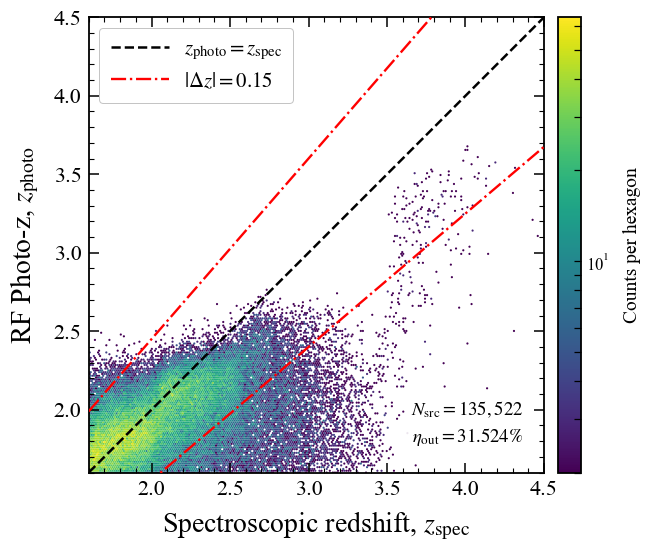

In [25]:
# ============================================================
# Large MNRAS-style figure
# Suitable for a double-column figure
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",

    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 15,

    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
})
# ============================================================
# Input data
# ============================================================
z_spec = RF[0]
z_median_RF = RF[1]
outlier_threshold=0.15
if z_spec.size != z_median_RF.size:
    raise ValueError(
        f"Array-length mismatch: "
        f"z_spec={z_spec.size:,}, "
        f"z_median={z_median_RF.size:,}"
    )

# ============================================================
# Analysis sample
# Used to calculate N_gal and the outlier fraction
# ============================================================
zspec_min = 1.6
zspec_max = 4.5

analysis_mask = (
    np.isfinite(z_spec)
    & np.isfinite(z_median_RF)
    & (z_spec >= zspec_min)
    & (z_spec <= zspec_max)
)

z_spec_analysis = z_spec[analysis_mask]
z_median_analysis = z_median_RF[analysis_mask]

# ============================================================
# Catastrophic-outlier definition
# ============================================================
delta_z_normalized = (
    z_median_analysis - z_spec_analysis
) / (1.0 + z_spec_analysis)

# Bias: median normalized residual
bias = np.median(delta_z_normalized)

# Mean bias, optional diagnostic
mean_bias = np.mean(delta_z_normalized)

# Normalized median absolute deviation
sigma_nmad = 1.4826 * np.median(
    np.abs(delta_z_normalized - bias)
)

# Catastrophic outliers
outlier_mask = (
    np.abs(delta_z_normalized) > outlier_threshold
)

n_gal = z_spec_analysis.size
n_outlier = np.count_nonzero(outlier_mask)
outlier_fraction = n_outlier / n_gal

print(f"Number of galaxies:  {n_gal:,}")
print(f"Median bias:         {bias:+.6f}")
print(f"Mean bias:           {mean_bias:+.6f}")
print(f"sigma_NMAD:          {sigma_nmad:.6f}")
print(f"Number of outliers:  {n_outlier:,}")
print(f"Outlier fraction:    {100 * outlier_fraction:.3f}%")
# ============================================================
# Plot range
#
# The plot range does not affect the outlier-fraction calculation.
# ============================================================
x_min, x_max = 1.6, 4.5
y_min, y_max = 1.6, 4.5

plot_mask = (
    (z_spec_analysis >= x_min)
    & (z_spec_analysis <= x_max)
    & (z_median_analysis >= y_min)
    & (z_median_analysis <= y_max)
)

z_spec_plot = z_spec_analysis[plot_mask]
z_median_plot = z_median_analysis[plot_mask]

# ============================================================
# Reference lines
# ============================================================
z_grid = np.linspace(x_min, x_max, 800)

upper_outlier = (
    z_grid
    + outlier_threshold * (1.0 + z_grid)
)

lower_outlier = (
    z_grid
    - outlier_threshold * (1.0 + z_grid)
)

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(6.8, 5.7))

hb = ax.hexbin(
    z_spec_plot,
    z_median_plot,
    gridsize=220,
    extent=(x_min, x_max, y_min, y_max),
    mincnt=2,
    norm=LogNorm(),
    cmap="viridis",
    linewidths=0,
    rasterized=True,
    zorder=1,
)

# One-to-one relation
ax.plot(
    z_grid,
    z_grid,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=r"$z_{\rm photo}=z_{\rm spec}$",
    zorder=5,
)

# Outlier boundaries
ax.plot(
    z_grid,
    upper_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    zorder=4,
)

ax.plot(
    z_grid,
    lower_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    label=rf"$|\Delta z|={outlier_threshold:.2f}$",
    zorder=4,
)

# ============================================================
# Axes formatting
# ============================================================
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$",
    labelpad=8,
)

ax.set_ylabel(
    r"RF Photo-z, $z_{\rm photo}$",
    labelpad=9,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    top=True,
    right=True,
    length=7,
    width=1.1,
    pad=5,
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=3.5,
    width=0.8,
)

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend
# ============================================================
legend = ax.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.94,
    facecolor="white",
    edgecolor="0.75",
    borderpad=0.55,
    labelspacing=0.45,
    handlelength=2.8,
    handletextpad=0.7,
)

legend.get_frame().set_linewidth(0.7)
legend.set_zorder(20)

# ============================================================
# Numerical annotation
# ============================================================
annotation = (
    rf"$N_{{\rm src}}={n_gal:,}$"
    "\n"
    rf"$\eta_{{\rm out}}={100*outlier_fraction:.3f}\%$"
)

ax.text(
    0.955,
    0.055,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13.5,
    linespacing=1.35,
    color="black",
    zorder=20,
     bbox={
        "boxstyle": "round,pad=0.30",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.90,
    },
)

# ============================================================
# Colorbar
# ============================================================
cbar = fig.colorbar(
    hb,
    ax=ax,
    pad=0.025,
    fraction=0.050,
)

cbar.set_label(
    "Counts per hexagon",
    fontsize=14,
    labelpad=10,
)

cbar.ax.tick_params(
    which="both",
    direction="in",
    labelsize=12,
    length=5,
    width=0.9,
)

# ============================================================
# Save
# ============================================================
fig.tight_layout(pad=0.8)

fig.savefig(
    "RF_zmedian_zspec_hexbin_large.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "RF_zmedian_zspec_hexbin_large.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()

Number of galaxies:  1,880,915
Median bias:         +0.000048
Mean bias:           +0.017414
sigma_NMAD:          0.026944
Number of outliers:  75,105
Outlier fraction:    3.993%


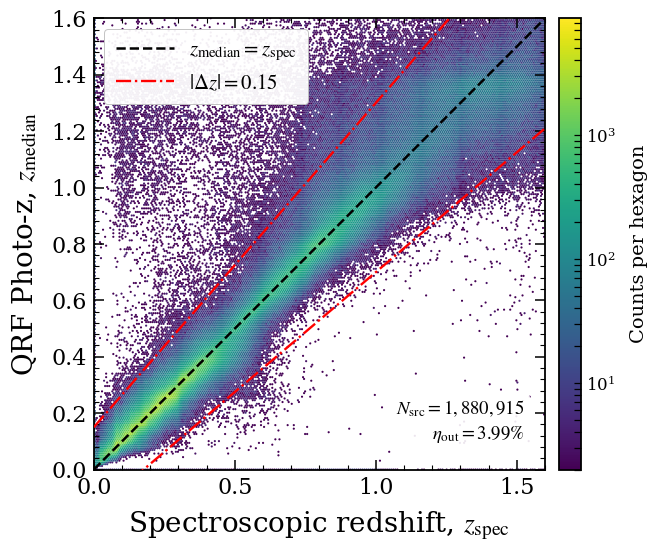

In [31]:
# ============================================================
# Large MNRAS-style figure
# Suitable for a double-column figure
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",

    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 15,

    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
})
# ============================================================
# Input data
# ============================================================
z_spec = QRF[0]
z_median_QRF = QRF[1]
outlier_threshold=0.15
if z_spec.size != z_median_QRF.size:
    raise ValueError(
        f"Array-length mismatch: "
        f"z_spec={z_spec.size:,}, "
        f"z_median={z_median_QRF.size:,}"
    )

# ============================================================
# Analysis sample
# Used to calculate N_gal and the outlier fraction
# ============================================================
zspec_min = 0.0
zspec_max = 1.6

analysis_mask = (
    np.isfinite(z_spec)
    & np.isfinite(z_median_QRF)
    & (z_spec >= zspec_min)
    & (z_spec <= zspec_max)
)

z_spec_analysis = z_spec[analysis_mask]
z_median_analysis = z_median_QRF[analysis_mask]

# ============================================================
# Catastrophic-outlier definition
# ============================================================
delta_z_normalized = (
    z_median_analysis - z_spec_analysis
) / (1.0 + z_spec_analysis)

# Bias: median normalized residual
bias = np.median(delta_z_normalized)

# Mean bias, optional diagnostic
mean_bias = np.mean(delta_z_normalized)

# Normalized median absolute deviation
sigma_nmad = 1.4826 * np.median(
    np.abs(delta_z_normalized - bias)
)

# Catastrophic outliers
outlier_mask = (
    np.abs(delta_z_normalized) > outlier_threshold
)

n_gal = z_spec_analysis.size
n_outlier = np.count_nonzero(outlier_mask)
outlier_fraction = n_outlier / n_gal

print(f"Number of galaxies:  {n_gal:,}")
print(f"Median bias:         {bias:+.6f}")
print(f"Mean bias:           {mean_bias:+.6f}")
print(f"sigma_NMAD:          {sigma_nmad:.6f}")
print(f"Number of outliers:  {n_outlier:,}")
print(f"Outlier fraction:    {100 * outlier_fraction:.3f}%")
# ============================================================
# Plot range
#
# The plot range does not affect the outlier-fraction calculation.
# ============================================================
x_min, x_max = 0.0, 1.6
y_min, y_max = 0.0, 1.6

plot_mask = (
    (z_spec_analysis >= x_min)
    & (z_spec_analysis <= x_max)
    & (z_median_analysis >= y_min)
    & (z_median_analysis <= y_max)
)

z_spec_plot = z_spec_analysis[plot_mask]
z_median_plot = z_median_analysis[plot_mask]

# ============================================================
# Reference lines
# ============================================================
z_grid = np.linspace(x_min, x_max, 800)

upper_outlier = (
    z_grid
    + outlier_threshold * (1.0 + z_grid)
)

lower_outlier = (
    z_grid
    - outlier_threshold * (1.0 + z_grid)
)

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(6.8, 5.7))

hb = ax.hexbin(
    z_spec_plot,
    z_median_plot,
    gridsize=220,
    extent=(x_min, x_max, y_min, y_max),
    mincnt=2,
    norm=LogNorm(),
    cmap="viridis",
    linewidths=0,
    rasterized=True,
    zorder=1,
)

# One-to-one relation
ax.plot(
    z_grid,
    z_grid,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=r"$z_{\rm median}=z_{\rm spec}$",
    zorder=5,
)

# Outlier boundaries
ax.plot(
    z_grid,
    upper_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    zorder=4,
)

ax.plot(
    z_grid,
    lower_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    label=rf"$|\Delta z|={outlier_threshold:.2f}$",
    zorder=4,
)

# ============================================================
# Axes formatting
# ============================================================
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$",
    labelpad=8,
)

ax.set_ylabel(
    r"QRF Photo-z, $z_{\rm median}$",
    labelpad=9,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    top=True,
    right=True,
    length=7,
    width=1.1,
    pad=5,
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=3.5,
    width=0.8,
)

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend
# ============================================================
legend = ax.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.94,
    facecolor="white",
    edgecolor="0.75",
    borderpad=0.55,
    labelspacing=0.45,
    handlelength=2.8,
    handletextpad=0.7,
)

legend.get_frame().set_linewidth(0.7)
legend.set_zorder(20)

# ============================================================
# Numerical annotation
# ============================================================
annotation = (
    rf"$N_{{\rm src}}={n_gal:,}$"
    "\n"
    rf"$\eta_{{\rm out}}={100*outlier_fraction:.2f}\%$"
)

ax.text(
    0.955,
    0.055,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13.5,
    linespacing=1.35,
    color="black",
    zorder=20,
     bbox={
        "boxstyle": "round,pad=0.30",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.90,
    },
)

# ============================================================
# Colorbar
# ============================================================
cbar = fig.colorbar(
    hb,
    ax=ax,
    pad=0.025,
    fraction=0.050,
)

cbar.set_label(
    "Counts per hexagon",
    fontsize=14,
    labelpad=10,
)

cbar.ax.tick_params(
    which="both",
    direction="in",
    labelsize=12,
    length=5,
    width=0.9,
)

# ============================================================
# Save
# ============================================================
fig.tight_layout(pad=0.8)

fig.savefig(
    "QRF_zmedian_zspec_hexbin_large.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "QRF_zmedian_zspec_hexbin_large.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()

Number of galaxies:  135,522
Median bias:         -0.063049
Mean bias:           -0.096240
sigma_NMAD:          0.112172
Number of outliers:  39,144
Outlier fraction:    28.884%


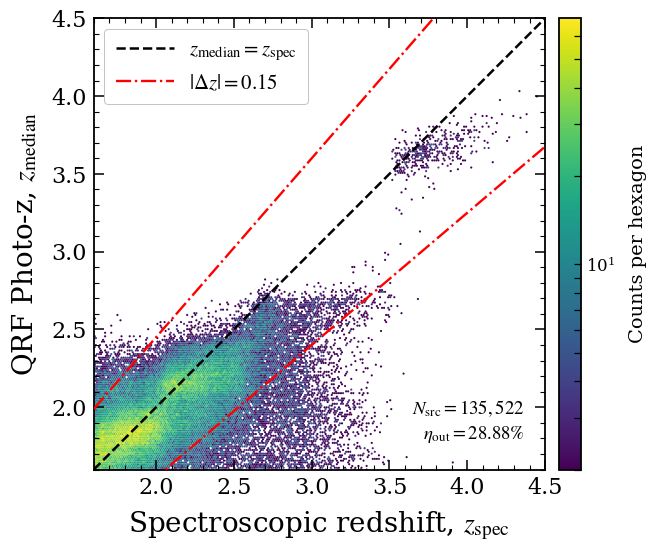

In [32]:
# ============================================================
# Large MNRAS-style figure
# Suitable for a double-column figure
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",

    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 15,

    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
})
# ============================================================
# Input data
# ============================================================
z_spec = QRF[0]
z_median_QRF = QRF[1]
outlier_threshold=0.15
if z_spec.size != z_median_QRF.size:
    raise ValueError(
        f"Array-length mismatch: "
        f"z_spec={z_spec.size:,}, "
        f"z_median={z_median_QRF.size:,}"
    )

# ============================================================
# Analysis sample
# Used to calculate N_gal and the outlier fraction
# ============================================================
zspec_min = 1.6
zspec_max = 4.5

analysis_mask = (
    np.isfinite(z_spec)
    & np.isfinite(z_median_QRF)
    & (z_spec >= zspec_min)
    & (z_spec <= zspec_max)
)

z_spec_analysis = z_spec[analysis_mask]
z_median_analysis = z_median_QRF[analysis_mask]

# ============================================================
# Catastrophic-outlier definition
# ============================================================
delta_z_normalized = (
    z_median_analysis - z_spec_analysis
) / (1.0 + z_spec_analysis)

# Bias: median normalized residual
bias = np.median(delta_z_normalized)

# Mean bias, optional diagnostic
mean_bias = np.mean(delta_z_normalized)

# Normalized median absolute deviation
sigma_nmad = 1.4826 * np.median(
    np.abs(delta_z_normalized - bias)
)

# Catastrophic outliers
outlier_mask = (
    np.abs(delta_z_normalized) > outlier_threshold
)

n_gal = z_spec_analysis.size
n_outlier = np.count_nonzero(outlier_mask)
outlier_fraction = n_outlier / n_gal

print(f"Number of galaxies:  {n_gal:,}")
print(f"Median bias:         {bias:+.6f}")
print(f"Mean bias:           {mean_bias:+.6f}")
print(f"sigma_NMAD:          {sigma_nmad:.6f}")
print(f"Number of outliers:  {n_outlier:,}")
print(f"Outlier fraction:    {100 * outlier_fraction:.3f}%")
# ============================================================
# Plot range
#
# The plot range does not affect the outlier-fraction calculation.
# ============================================================
x_min, x_max = 1.6, 4.5
y_min, y_max = 1.6, 4.5

plot_mask = (
    (z_spec_analysis >= x_min)
    & (z_spec_analysis <= x_max)
    & (z_median_analysis >= y_min)
    & (z_median_analysis <= y_max)
)

z_spec_plot = z_spec_analysis[plot_mask]
z_median_plot = z_median_analysis[plot_mask]

# ============================================================
# Reference lines
# ============================================================
z_grid = np.linspace(x_min, x_max, 800)

upper_outlier = (
    z_grid
    + outlier_threshold * (1.0 + z_grid)
)

lower_outlier = (
    z_grid
    - outlier_threshold * (1.0 + z_grid)
)

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(6.8, 5.7))

hb = ax.hexbin(
    z_spec_plot,
    z_median_plot,
    gridsize=220,
    extent=(x_min, x_max, y_min, y_max),
    mincnt=2,
    norm=LogNorm(),
    cmap="viridis",
    linewidths=0,
    rasterized=True,
    zorder=1,
)

# One-to-one relation
ax.plot(
    z_grid,
    z_grid,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=r"$z_{\rm median}=z_{\rm spec}$",
    zorder=5,
)

# Outlier boundaries
ax.plot(
    z_grid,
    upper_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    zorder=4,
)

ax.plot(
    z_grid,
    lower_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    label=rf"$|\Delta z|={outlier_threshold:.2f}$",
    zorder=4,
)

# ============================================================
# Axes formatting
# ============================================================
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$",
    labelpad=8,
)

ax.set_ylabel(
    r"QRF Photo-z, $z_{\rm median}$",
    labelpad=9,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    top=True,
    right=True,
    length=7,
    width=1.1,
    pad=5,
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=3.5,
    width=0.8,
)

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend
# ============================================================
legend = ax.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.94,
    facecolor="white",
    edgecolor="0.75",
    borderpad=0.55,
    labelspacing=0.45,
    handlelength=2.8,
    handletextpad=0.7,
)

legend.get_frame().set_linewidth(0.7)
legend.set_zorder(20)

# ============================================================
# Numerical annotation
# ============================================================
annotation = (
    rf"$N_{{\rm src}}={n_gal:,}$"
    "\n"
    rf"$\eta_{{\rm out}}={100*outlier_fraction:.2f}\%$"
)

ax.text(
    0.955,
    0.055,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13.5,
    linespacing=1.35,
    color="black",
    zorder=20,
     bbox={
        "boxstyle": "round,pad=0.30",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.90,
    },
)

# ============================================================
# Colorbar
# ============================================================
cbar = fig.colorbar(
    hb,
    ax=ax,
    pad=0.025,
    fraction=0.050,
)

cbar.set_label(
    "Counts per hexagon",
    fontsize=14,
    labelpad=10,
)

cbar.ax.tick_params(
    which="both",
    direction="in",
    labelsize=12,
    length=5,
    width=0.9,
)

# ============================================================
# Save
# ============================================================
fig.tight_layout(pad=0.8)

fig.savefig(
    "QRF_zmedian_zspec_hexbin_large.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "QRF_zmedian_zspec_hexbin_large.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()

Number of galaxies:  1,880,920
Median bias:         -0.000125
Mean bias:           +0.015055
sigma_NMAD:          0.022333
Number of outliers:  70,413
Outlier fraction:    3.7435%


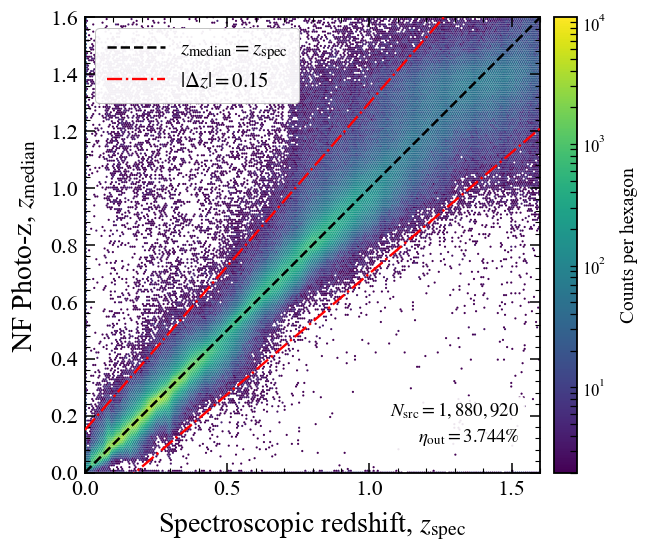

In [22]:
# ============================================================
# Large MNRAS-style figure
# Suitable for a double-column figure
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",

    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 15,

    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
})
# ============================================================
# Input data
# ============================================================
z_spec = np.asarray(zs).reshape(-1)
z_median_NF = z_median

if z_spec.size != z_median.size:
    raise ValueError(
        f"Array-length mismatch: "
        f"z_spec={z_spec.size:,}, "
        f"z_median={z_median.size:,}"
    )

# ============================================================
# Analysis sample
# Used to calculate N_gal and the outlier fraction
# ============================================================
zspec_min = 0.0
zspec_max = 1.6

analysis_mask = (
    np.isfinite(z_spec)
    & np.isfinite(z_median)
    & (z_spec >= zspec_min)
    & (z_spec <= zspec_max)
)

z_spec_analysis = z_spec[analysis_mask]
z_median_analysis = z_median_NF[analysis_mask]
outlier_threshold=0.15
# ============================================================
# Catastrophic-outlier definition
# ============================================================
delta_z_normalized = (
    z_median_analysis - z_spec_analysis
) / (1.0 + z_spec_analysis)

# Bias: median normalized residual
bias = np.median(delta_z_normalized)

# Mean bias, optional diagnostic
mean_bias = np.mean(delta_z_normalized)

# Normalized median absolute deviation
sigma_nmad = 1.4826 * np.median(
    np.abs(delta_z_normalized - bias)
)

# Catastrophic outliers
outlier_mask = (
    np.abs(delta_z_normalized) > outlier_threshold
)

n_gal = z_spec_analysis.size
n_outlier = np.count_nonzero(outlier_mask)
outlier_fraction = n_outlier / n_gal

print(f"Number of galaxies:  {n_gal:,}")
print(f"Median bias:         {bias:+.6f}")
print(f"Mean bias:           {mean_bias:+.6f}")
print(f"sigma_NMAD:          {sigma_nmad:.6f}")
print(f"Number of outliers:  {n_outlier:,}")
print(f"Outlier fraction:    {100 * outlier_fraction:.4f}%")

# ============================================================
# Plot range
#
# The plot range does not affect the outlier-fraction calculation.
# ============================================================
x_min, x_max = 0.0, 1.6
y_min, y_max = 0.0, 1.6

plot_mask = (
    (z_spec_analysis >= x_min)
    & (z_spec_analysis <= x_max)
    & (z_median_analysis >= y_min)
    & (z_median_analysis <= y_max)
)

z_spec_plot = z_spec_analysis[plot_mask]
z_median_plot = z_median_analysis[plot_mask]

# ============================================================
# Reference lines
# ============================================================
z_grid = np.linspace(x_min, x_max, 800)

upper_outlier = (
    z_grid
    + outlier_threshold * (1.0 + z_grid)
)

lower_outlier = (
    z_grid
    - outlier_threshold * (1.0 + z_grid)
)

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(6.8, 5.7))

hb = ax.hexbin(
    z_spec_plot,
    z_median_plot,
    gridsize=220,
    extent=(x_min, x_max, y_min, y_max),
    mincnt=2,
    norm=LogNorm(),
    cmap="viridis",
    linewidths=0,
    rasterized=True,
    zorder=1,
)

# One-to-one relation
ax.plot(
    z_grid,
    z_grid,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=r"$z_{\rm median}=z_{\rm spec}$",
    zorder=5,
)

# Outlier boundaries
ax.plot(
    z_grid,
    upper_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    zorder=4,
)

ax.plot(
    z_grid,
    lower_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    label=rf"$|\Delta z|={outlier_threshold:.2f}$",
    zorder=4,
)

# ============================================================
# Axes formatting
# ============================================================
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$",
    labelpad=8,
)

ax.set_ylabel(
    r"NF Photo-z, $z_{\rm median}$",
    labelpad=9,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    top=True,
    right=True,
    length=7,
    width=1.1,
    pad=5,
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=3.5,
    width=0.8,
)

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend
# ============================================================
legend = ax.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.94,
    facecolor="white",
    edgecolor="0.75",
    borderpad=0.55,
    labelspacing=0.45,
    handlelength=2.8,
    handletextpad=0.7,
)

legend.get_frame().set_linewidth(0.7)
legend.set_zorder(20)

# ============================================================
# Numerical annotation
# ============================================================
annotation = (
    rf"$N_{{\rm src}}={n_gal:,}$"
    "\n"
    rf"$\eta_{{\rm out}}={100*outlier_fraction:.3f}\%$"
)

ax.text(
    0.955,
    0.055,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13.5,
    linespacing=1.35,
    color="black",
    zorder=20,
     bbox={
        "boxstyle": "round,pad=0.30",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.90,
    },
)

# ============================================================
# Colorbar
# ============================================================
cbar = fig.colorbar(
    hb,
    ax=ax,
    pad=0.025,
    fraction=0.050,
)

cbar.set_label(
    "Counts per hexagon",
    fontsize=14,
    labelpad=10,
)

cbar.ax.tick_params(
    which="both",
    direction="in",
    labelsize=12,
    length=5,
    width=0.9,
)

# ============================================================
# Save
# ============================================================
fig.tight_layout(pad=0.8)

fig.savefig(
    "NF_zmedian_zspec_hexbin_large.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "NF_zmedian_zspec_hexbin_large.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()

Number of galaxies:  135,522
Median bias:         -0.046775
Mean bias:           -0.087339
sigma_NMAD:          0.102655
Number of outliers:  35,750
Outlier fraction:    26.3795%


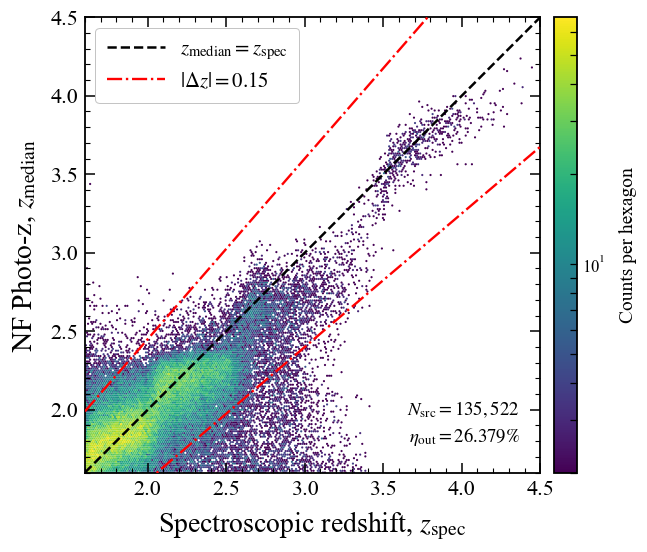

In [23]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",

    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 15,

    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
})
# ============================================================
# Input data
# ============================================================
z_spec = np.asarray(zs).reshape(-1)
z_median_NF = z_median

if z_spec.size != z_median.size:
    raise ValueError(
        f"Array-length mismatch: "
        f"z_spec={z_spec.size:,}, "
        f"z_median={z_median.size:,}"
    )

# ============================================================
# Analysis sample
# Used to calculate N_gal and the outlier fraction
# ============================================================
zspec_min = 1.6
zspec_max = 4.5

analysis_mask = (
    np.isfinite(z_spec)
    & np.isfinite(z_median)
    & (z_spec >= zspec_min)
    & (z_spec <= zspec_max)
)

z_spec_analysis = z_spec[analysis_mask]
z_median_analysis = z_median_NF[analysis_mask]
outlier_threshold=0.15
# ============================================================
# Catastrophic-outlier definition
# ============================================================
delta_z_normalized = (
    z_median_analysis - z_spec_analysis
) / (1.0 + z_spec_analysis)

# Bias: median normalized residual
bias = np.median(delta_z_normalized)

# Mean bias, optional diagnostic
mean_bias = np.mean(delta_z_normalized)

# Normalized median absolute deviation
sigma_nmad = 1.4826 * np.median(
    np.abs(delta_z_normalized - bias)
)

# Catastrophic outliers
outlier_mask = (
    np.abs(delta_z_normalized) > outlier_threshold
)

n_gal = z_spec_analysis.size
n_outlier = np.count_nonzero(outlier_mask)
outlier_fraction = n_outlier / n_gal

print(f"Number of galaxies:  {n_gal:,}")
print(f"Median bias:         {bias:+.6f}")
print(f"Mean bias:           {mean_bias:+.6f}")
print(f"sigma_NMAD:          {sigma_nmad:.6f}")
print(f"Number of outliers:  {n_outlier:,}")
print(f"Outlier fraction:    {100 * outlier_fraction:.4f}%")

# ============================================================
# Plot range
#
# The plot range does not affect the outlier-fraction calculation.
# ============================================================
x_min, x_max = 1.6, 4.5
y_min, y_max = 1.6, 4.5

plot_mask = (
    (z_spec_analysis >= x_min)
    & (z_spec_analysis <= x_max)
    & (z_median_analysis >= y_min)
    & (z_median_analysis <= y_max)
)

z_spec_plot = z_spec_analysis[plot_mask]
z_median_plot = z_median_analysis[plot_mask]

# ============================================================
# Reference lines
# ============================================================
z_grid = np.linspace(x_min, x_max, 800)

upper_outlier = (
    z_grid
    + outlier_threshold * (1.0 + z_grid)
)

lower_outlier = (
    z_grid
    - outlier_threshold * (1.0 + z_grid)
)

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(figsize=(6.8, 5.7))

hb = ax.hexbin(
    z_spec_plot,
    z_median_plot,
    gridsize=220,
    extent=(x_min, x_max, y_min, y_max),
    mincnt=2,
    norm=LogNorm(),
    cmap="viridis",
    linewidths=0,
    rasterized=True,
    zorder=1,
)

# One-to-one relation
ax.plot(
    z_grid,
    z_grid,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=r"$z_{\rm median}=z_{\rm spec}$",
    zorder=5,
)

# Outlier boundaries
ax.plot(
    z_grid,
    upper_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    zorder=4,
)

ax.plot(
    z_grid,
    lower_outlier,
    color="red",
    linestyle="-.",
    linewidth=1.7,
    label=rf"$|\Delta z|={outlier_threshold:.2f}$",
    zorder=4,
)

# ============================================================
# Axes formatting
# ============================================================
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    r"Spectroscopic redshift, $z_{\rm spec}$",
    labelpad=8,
)

ax.set_ylabel(
    r"NF Photo-z, $z_{\rm median}$",
    labelpad=9,
)

ax.tick_params(
    axis="both",
    which="major",
    direction="in",
    top=True,
    right=True,
    length=7,
    width=1.1,
    pad=5,
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=3.5,
    width=0.8,
)

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

# ============================================================
# Legend
# ============================================================
legend = ax.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.94,
    facecolor="white",
    edgecolor="0.75",
    borderpad=0.55,
    labelspacing=0.45,
    handlelength=2.8,
    handletextpad=0.7,
)

legend.get_frame().set_linewidth(0.7)
legend.set_zorder(20)

# ============================================================
# Numerical annotation
# ============================================================
annotation = (
    rf"$N_{{\rm src}}={n_gal:,}$"
    "\n"
    rf"$\eta_{{\rm out}}={100*outlier_fraction:.3f}\%$"
)

ax.text(
    0.955,
    0.055,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=13.5,
    linespacing=1.35,
    color="black",
    zorder=20,
     bbox={
        "boxstyle": "round,pad=0.30",
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.90,
    },
)

# ============================================================
# Colorbar
# ============================================================
cbar = fig.colorbar(
    hb,
    ax=ax,
    pad=0.025,
    fraction=0.050,
)

cbar.set_label(
    "Counts per hexagon",
    fontsize=14,
    labelpad=10,
)

cbar.ax.tick_params(
    which="both",
    direction="in",
    labelsize=12,
    length=5,
    width=0.9,
)

# ============================================================
# Save
# ============================================================
fig.tight_layout(pad=0.8)

fig.savefig(
    "NF_zmedian_zspec_hexbin_large.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "NF_zmedian_zspec_hexbin_large.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()

## 8. Feature saliency
Input-gradient saliency is evaluated using the **loaded/trained** flow transforms. The older duplicate saliency implementation and the cell that recreated a fresh, untrained transform have been removed.


In [25]:
# Use the trained transform returned by load_model; do not recreate a fresh flow here.
train_loader = DataLoader(
    TensorDataset(x1_train, x2_train),
    batch_size=batch_size,
    shuffle=True,
)


In [26]:
def flow_parameter_significance(
    x2_transform,
    dist_x2_given_x1,
    loader,
    device=None,
    max_batches=None,
):
    """
    Estimate feature significance for a conditional flow p(x2 | x1)
    using input-gradient saliency.

    Returns
    -------
    median_sal : ndarray
        Median absolute saliency for each feature.

    rel_imp : ndarray
        Median saliency normalized by the largest median saliency.

    spread : ndarray, shape (2, n_features)
        Asymmetric 16th--84th percentile range, normalized by the
        same maximum median saliency.
        spread[0] = lower error
        spread[1] = upper error
    """

    if device is None:
        device = next(x2_transform.parameters()).device

    x2_transform.eval()

    all_saliency = []

    for b, batch in enumerate(loader):

        if max_batches is not None and b >= max_batches:
            break

        if isinstance(batch, (list, tuple)) and len(batch) >= 2:
            x1_batch, x2_batch = batch[0], batch[1]
        else:
            raise RuntimeError(
                "Adjust batch unpacking to match DataLoader output."
            )

        # Use the actual batch
        x1_batch = (
            x1_batch
            .to(device)
            .detach()
            .requires_grad_(True)
        )

        x2_batch = x2_batch.to(device)

        # Conditional distribution
        cond_dist = dist_x2_given_x1.condition(x1_batch)

        logp = cond_dist.log_prob(x2_batch)

        # Sum gives per-object gradients without 1/B scaling
        loss = -logp.sum()

        grad = torch.autograd.grad(
            loss,
            x1_batch,
            retain_graph=False,
            create_graph=False,
        )[0]

        batch_saliency = grad.detach().abs().cpu()

        all_saliency.append(batch_saliency)

    # (N_objects, N_features)
    saliency = torch.cat(all_saliency, dim=0)

    print("Saliency shape:", saliency.shape)

    # Robust statistics
    median_sal = torch.median(saliency, dim=0).values
    q16 = torch.quantile(saliency, 0.16, dim=0)
    q84 = torch.quantile(saliency, 0.84, dim=0)

    median_sal_np = median_sal.numpy()
    q16_np = q16.numpy()
    q84_np = q84.numpy()

    # Normalize using maximum MEDIAN saliency
    norm = median_sal_np.max()

    rel_imp = median_sal_np / norm

    # asymmetric percentile ranges
    lower = (median_sal_np - q16_np) / norm
    upper = (q84_np - median_sal_np) / norm

    spread = np.vstack([lower, upper])

    return median_sal_np, rel_imp, spread

In [27]:
device = next(x2_transform.parameters()).device
median_sal, rel_imp, spread = flow_parameter_significance(
    x2_transform,
    dist_x2_given_x1,
    train_loader,       # your training DataLoader
    device=device,
    max_batches=200,    # optional, for speed
)


Saliency shape: torch.Size([51200, 23])


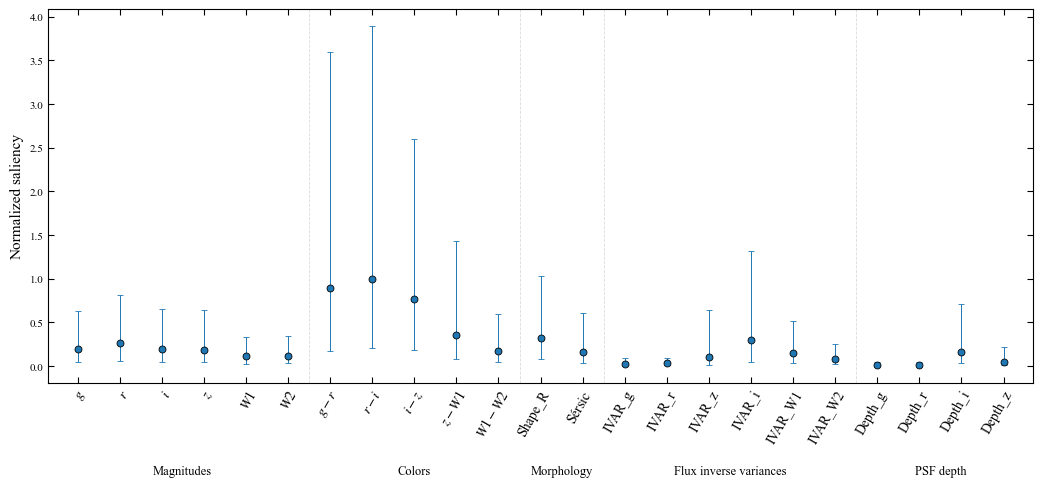

In [28]:
idx = np.arange(len(median_sal))

param_names = [
    r"$g$", r"$r$", r"$i$", r"$z$", r"$W1$", r"$W2$",
    r"$g-r$", r"$r-i$", r"$i-z$", r"$z-W1$", r"$W1-W2$",
    "Shape_R", r"${\rm Sérsic}$",
    "IVAR_g", "IVAR_r",
    "IVAR_z", "IVAR_i",
    "IVAR_W1", "IVAR_W2",
    "Depth_g", "Depth_r",
    "Depth_i", "Depth_z"
]

fig, ax = plt.subplots(figsize=(10.5, 4.8))

ax.errorbar(
    idx,
    rel_imp,
    yerr=spread,
    fmt="o",
    markersize=5,
    markeredgecolor="black",
    markeredgewidth=0.6,
    elinewidth=0.7,
    capsize=2,
    capthick=0.7
)
ax.set_xticks(idx)
ax.set_xticklabels(
    param_names,
    rotation=60,
    ha="right",
    rotation_mode="anchor",
    fontsize=10
)

ax.set_ylabel("Normalized saliency", fontsize=11)

ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.set_xlim(-0.7, len(idx) - 0.3)
groups = [
    (0, 5, "Magnitudes"),
    (6, 10, "Colors"),
    (11, 12, "Morphology"),
    (13, 18, "Flux inverse variances"),
    (19, 22, "PSF depth"),
]
for start, end, label in groups:
    centre = (start + end) / 2
    ax.text(
        centre,
        -0.22,   # 原来如果是 -0.28，可以改近一些
        label,
        ha="center",
        va="top",
        transform=ax.get_xaxis_transform(),
        fontsize=9
    )
for x in [5.5, 10.5, 12.5, 18.5]:
    ax.axvline(
        x,
        color="0.8",
        linestyle="--",
        linewidth=0.6,
        alpha=0.7,
    )

for spine in ax.spines.values():
    spine.set_linewidth(0.8)
plt.subplots_adjust(bottom=0.24)

plt.tight_layout()
plt.savefig(
    "feature_saliency.pdf",
    bbox_inches="tight"
)
plt.show()


## ECDF Calibration

Derive the ECDF-based calibration mapping from the NF predictions on the validation sample, save the mapping, and apply it to the independent testing sample. Then evaluate the improvement in the PIT distribution and generate the recalibrated PDFs for the testing sample.


In [23]:
#output validation samples NF PDFs prediction
zs_val = scaler_x.inverse_transform(x2_validate.detach().cpu().numpy().reshape(-1, 1)).flatten()
x2_flow_val,z_maxp_val, z_median_val, z_mean_val, err_std_val, err_68halfpc_val= test_sample_dist( x1_validate, x2_validate, zs_val, mean, std )

In [24]:
from tqdm.auto import tqdm
def evaluate_base_cdf(base_dist, latent):
    """
    Evaluate a one-dimensional base-distribution CDF.
    """

    if isinstance(base_dist, torch.distributions.Independent):
        return base_dist.base_dist.cdf(latent)

    return base_dist.cdf(latent)


@torch.no_grad()
def calculate_exact_pit_manual(
    dist_x2_given_x1,
    x2_transform,
    x1_test,
    x2_test,
    chunk_size=20_000,
):
    x2_transform.eval()

    parameter = next(x2_transform.parameters())
    device = parameter.device
    dtype = parameter.dtype

    x1_test = torch.as_tensor(
        x1_test,
        dtype=dtype,
        device=device,
    )

    x2_test = torch.as_tensor(
        x2_test,
        dtype=dtype,
        device=device,
    ).reshape(-1, 1)

    pit_chunks = []

    for start in tqdm(
        range(0, len(x2_test), chunk_size),
        desc="Exact PIT",
    ):
        stop = min(start + chunk_size, len(x2_test))

        context_chunk = x1_test[start:stop]
        redshift_chunk = x2_test[start:stop]

        conditioned_dist = dist_x2_given_x1.condition(
            context_chunk
        )

        latent = redshift_chunk

        # Correct: reverse the transform list.
        for transform in conditioned_dist.transforms[::-1]:
            latent = transform.inv(latent)

        pit_chunk = evaluate_base_cdf(
            conditioned_dist.base_dist,
            latent,
        )

        pit_chunks.append(
            pit_chunk.reshape(-1).cpu()
        )

    pit = torch.cat(pit_chunks).numpy()

    return np.clip(pit, 0.0, 1.0)

In [25]:
def fit_pit_mapping(pit, n_knots=101):
    """
    Fit empirical PIT recalibration mapping.

    Returns
    -------
    q_knots : calibrated quantile levels
    u_knots : corresponding raw PIT values
    """

    pit = np.asarray(pit)
    pit = pit[np.isfinite(pit)]
    pit = np.clip(pit, 0.0, 1.0)

    q_knots = np.linspace(0.0, 1.0, n_knots)

    # G^{-1}(q)
    u_knots = np.quantile(
        pit,
        q_knots
    )

    # force exact boundaries
    u_knots[0] = 0.0
    u_knots[-1] = 1.0

    return q_knots, u_knots

In [26]:
#calculate the origional PIT for testing samples
pit_exact=calculate_exact_pit_manual(
    dist_x2_given_x1,
    x2_transform,
    x1_test,
    x2_test,
    chunk_size=50_000,
)

Exact PIT:   0%|          | 0/41 [00:00<?, ?it/s]

In [27]:
#calculate the validation samples PIT
pit_val=calculate_exact_pit_manual(
    dist_x2_given_x1,
    x2_transform,
    x1_validate,
    x2_validate,
    chunk_size=50_000,
)

Exact PIT:   0%|          | 0/3 [00:00<?, ?it/s]

In [28]:
#define tomographic bins and mask
z_bins=[[0.0,0.2],[0.2,0.4],[0.4,0.8],[0.8,1.6],[1.6,2.5],[2.5,4.5]]
z_median_val_1=z_median_val
z_median_1=z_median

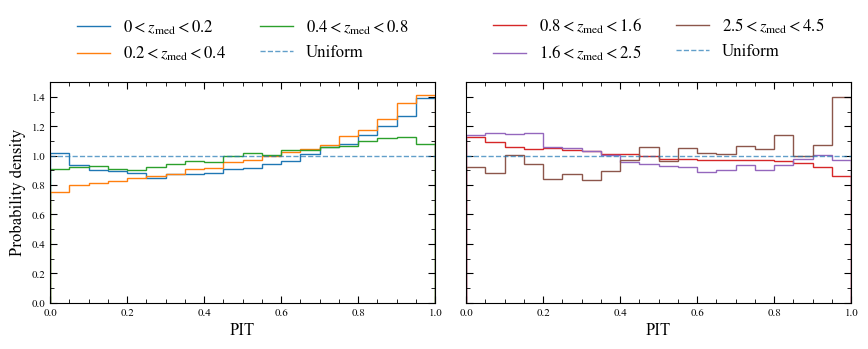

In [29]:
pit_bins = np.linspace(0, 1, 21)

fig, axes = plt.subplots(
    1, 2, figsize=(9.0, 3.8),
    sharex=True, sharey=True
)

split = len(z_bins) // 2
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i, (z_min, z_max) in enumerate(z_bins):

    ax = axes[0] if i < split else axes[1]

    mask = (
        np.isfinite(z_median_1)
        & np.isfinite(pit_exact)
        & (z_median_1 >= z_min)
        & (z_median_1 < z_max)
    )

    pit_bin = pit_exact[mask]
    h, edges = np.histogram(pit_bin, bins=pit_bins, density=True)

    label = (
        rf"$z_{{\rm med}}>{z_min:g}$"
        if np.isinf(z_max)
        else rf"${z_min:g}<z_{{\rm med}}<{z_max:g}$"
    )

    ax.stairs(
        h, edges,
        color=colors[i],
        linewidth=1.0,
        label=label
    )

for ax in axes:
    ax.axhline(
    1.0,
    linestyle='--',
    linewidth=1.0,
    alpha=0.7,
    label='Uniform'
    )
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.5)
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

    ax.tick_params(
        axis='both', which='major',
        labelsize=8, length=5,
        direction='in', top=True, right=True
    )
    ax.tick_params(
        axis='both', which='minor',
        length=3, direction='in',
        top=True, right=True
    )

    ax.xaxis.set_minor_locator(AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

    ax.legend(
        fontsize=12,
        frameon=False,
        loc='lower center',
        bbox_to_anchor=(0.5, 1.02),
        ncol=2
    )

axes[0].set_ylabel('Probability density', fontsize=12)
axes[0].set_xlabel('PIT', fontsize=12)
axes[1].set_xlabel('PIT', fontsize=12)
fig.subplots_adjust(
    left=0.09, right=0.98,
    bottom=0.17, top=0.75,
    wspace=0.08
)

plt.show()

In [30]:
#calibration on 4 tomographic bins respectively
calibrators = {}

for i, (zmin, zmax) in enumerate(z_bins):

    mask = (
        (z_median_val_1>= zmin)
        & (z_median_val_1 < zmax)
    )

    q_knots, u_knots = fit_pit_mapping(
        pit_val[mask],
        n_knots=101,
    )

    calibrators[i] = {
        "q": q_knots,
        "u": u_knots,
    }

In [31]:
def calibrate_pit(pit, q_knots, u_knots):

    # remove repeated u values for interpolation
    u_unique, index = np.unique(
        u_knots,
        return_index=True
    )

    q_unique = q_knots[index]

    return np.interp(
        pit,
        u_unique,
        q_unique,
        left=0.0,
        right=1.0,
    )

In [32]:
#output validation samples calibrated PIT
pit_val_cal = np.zeros_like(pit_val)

for i, (zmin, zmax) in enumerate(z_bins):

    mask = (
        (z_median_val_1 >= zmin)
        & (z_median_val_1 < zmax)
    )

    pit_val_cal[mask] = calibrate_pit(
        pit_val[mask],
        calibrators[i]["q"],
        calibrators[i]["u"],
    )

In [33]:
#output testing samples calibrated PIT
pit_test_cal = np.zeros_like(pit_exact)

for i, (zmin, zmax) in enumerate(z_bins):

    mask = (
        (z_median_1 >= zmin)
        & (z_median_1 < zmax)
    )

    pit_test_cal[mask] = calibrate_pit(
        pit_exact[mask],
        calibrators[i]["q"],
        calibrators[i]["u"],
    )

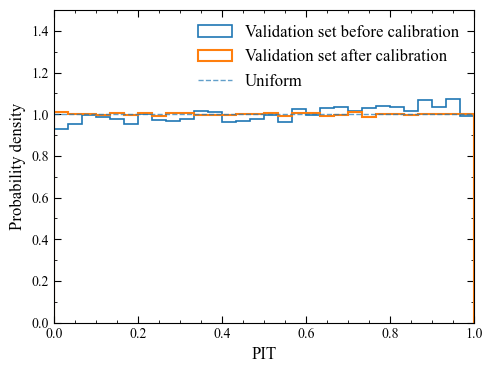

In [34]:
fig, ax = plt.subplots(figsize=(5.0, 3.8))

bins = np.linspace(0.0, 1.0, 31)

# Before calibration
ax.hist(
    pit_val,
    bins=bins,
    density=True,
    histtype='step',
    linewidth=1.2,
    label='Validation set before calibration'
)

# After calibration
ax.hist(
    pit_val_cal,
    bins=bins,
    density=True,
    histtype='step',
    linewidth=1.5,
    label='Validation set after calibration'
)

# Ideal PIT distribution
ax.axhline(
    1.0,
    linestyle='--',
    linewidth=1.0,
    alpha=0.7,
    label='Uniform'
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.5)

ax.set_xlabel('PIT',fontsize=12)
ax.set_ylabel('Probability density',fontsize=12)

# MNRAS-like ticks
ax.tick_params(
    axis='both',
    which='both',
    direction='in',
    top=True,
    right=True,
    labelsize=10
)

ax.tick_params(which='major', length=5)
ax.tick_params(which='minor', length=2.5)

ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_minor_locator(AutoMinorLocator(2))

# Legend
ax.legend(
    frameon=False,
    fontsize=12,
    loc='best'
)

# Slightly thinner spines
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

fig.tight_layout()
plt.show()

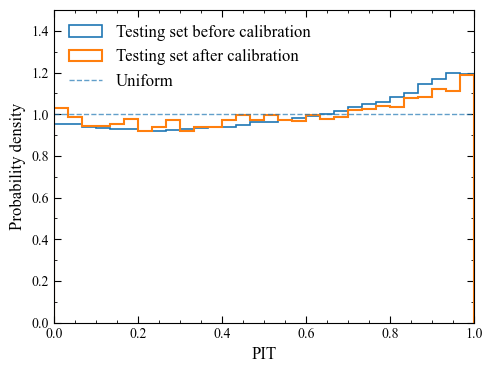

In [35]:
fig, ax = plt.subplots(figsize=(5.0, 3.8))

bins = np.linspace(0.0, 1.0, 31)

# Before calibration
ax.hist(
    pit_exact,
    bins=bins,
    density=True,
    histtype='step',
    linewidth=1.2,
    label='Testing set before calibration'
)

# After calibration
ax.hist(
    pit_test_cal,
    bins=bins,
    density=True,
    histtype='step',
    linewidth=1.5,
    label='Testing set after calibration'
)

# Ideal PIT distribution
ax.axhline(
    1.0,
    linestyle='--',
    linewidth=1.0,
    alpha=0.7,
    label='Uniform'
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.5)


ax.set_xlabel('PIT',fontsize=12)
ax.set_ylabel('Probability density',fontsize=12)

# MNRAS-like ticks
ax.tick_params(
    axis='both',
    which='both',
    direction='in',
    top=True,
    right=True,
    labelsize=10
)

ax.tick_params(which='major', length=5)
ax.tick_params(which='minor', length=2.5)

ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_minor_locator(AutoMinorLocator(2))

# Legend
ax.legend(
    frameon=False,
    fontsize=12,
    loc='best'
)

# Slightly thinner spines
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

fig.tight_layout()
plt.show()

D_PIT before = 0.03494
D_PIT after  = 0.02360


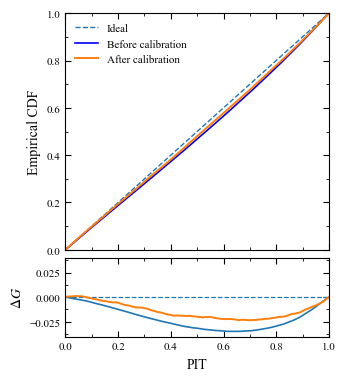

In [36]:
def empirical_cdf(pit):
    pit = np.asarray(pit)
    pit = pit[np.isfinite(pit)]
    pit = np.sort(pit)

    n = len(pit)
    ecdf = np.arange(1, n + 1) / n

    return pit, ecdf


# -------------------------------------------------
# Compute empirical CDFs
# -------------------------------------------------

x_before, y_before = empirical_cdf(pit_exact)
x_after,  y_after  = empirical_cdf(pit_test_cal)

# Residual relative to ideal G(u) = u
res_before = y_before - x_before
res_after  = y_after  - x_after

# KS-like maximum deviations
D_before = np.max(np.abs(res_before))
D_after  = np.max(np.abs(res_after))

print(f"D_PIT before = {D_before:.5f}")
print(f"D_PIT after  = {D_after:.5f}")


# -------------------------------------------------
# Downsample only for plotting
# -------------------------------------------------

nplot = 3000

step_before = max(1, len(x_before) // nplot)
step_after  = max(1, len(x_after) // nplot)

xb = x_before[::step_before]
yb = y_before[::step_before]
rb = res_before[::step_before]

xa = x_after[::step_after]
ya = y_after[::step_after]
ra = res_after[::step_after]


# -------------------------------------------------
# MNRAS-style figure
# -------------------------------------------------

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(3.4, 4.2),
    sharex=True,
    gridspec_kw={
        'height_ratios': [3.0, 1.0],
        'hspace': 0.05
    }
)


# =========================
# Upper panel: empirical CDF
# =========================

ax.plot(
    [0, 1], [0, 1],
    ls='--',
    lw=1.0,
    label='Ideal'
)

ax.plot(
    xb, yb,
    lw=1.2,
    label='Before calibration',
    c='blue'
)

ax.plot(
    xa, ya,
    lw=1.4,
    label='After calibration'
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_ylabel('Empirical CDF')

ax.legend(
    frameon=False,
    fontsize=8,
    loc='upper left'
)


# =========================
# Lower panel: residual
# =========================

axr.axhline(
    0,
    ls='--',
    lw=0.9
)

axr.plot(
    xb, rb,
    lw=1.2,
    label='Before calibration'
)

axr.plot(
    xa, ra,
    lw=1.4,
    label='After calibration'
)

axr.set_xlim(0, 1)

axr.set_xlabel('PIT')
axr.set_ylabel(r'$\Delta G$')


# Symmetric residual range
max_res = max(
    np.max(np.abs(res_before)),
    np.max(np.abs(res_after))
)

axr.set_ylim(
    -1.15 * max_res,
     1.15 * max_res
)


# -------------------------------------------------
# MNRAS-like ticks
# -------------------------------------------------

for a in (ax, axr):

    a.tick_params(
        axis='both',
        which='both',
        direction='in',
        top=True,
        right=True,
        labelsize=8
    )

    a.tick_params(
        which='major',
        length=4
    )

    a.tick_params(
        which='minor',
        length=2
    )

    a.xaxis.set_minor_locator(
        AutoMinorLocator(2)
    )

    a.yaxis.set_minor_locator(
        AutoMinorLocator(2)
    )

    for spine in a.spines.values():
        spine.set_linewidth(0.8)


plt.show()

In [37]:
def recalibrate_pdfs_four_bins(
    NF_samples,
    zmedian,
    calibrators,
    z_bins=z_bins,
    n_samples=200,
    chunk_size=100_000,
):
    """
    Apply redshift-dependent PIT/CDF recalibration to NF PDFs.

    Parameters
    ----------
    NF_samples : ndarray
        Raw NF Monte Carlo PDF samples.
        Shape = (N_gal, n_samples)

    zmedian : ndarray
        Raw NF posterior median used to assign galaxies
        to calibration bins.
        Shape = (N_gal,)

    calibrators : dict
        calibrators[i]["q"] = calibrated quantile grid
        calibrators[i]["u"] = corresponding raw quantiles,
        i.e. G_i^{-1}(q)

    z_bins : list
        Redshift bins for calibration.

    n_samples : int
        Number of samples used to represent each calibrated PDF.

    chunk_size : int
        Number of galaxies processed at once.

    Returns
    -------
    calibrated_samples : ndarray
        Calibrated PDF samples.
        Shape = (N_gal, n_samples)
    """

    NF_samples = np.asarray(NF_samples)
    zmedian = np.asarray(zmedian)

    n_gal = len(zmedian)

    calibrated_samples = np.empty(
        (n_gal, n_samples),
        dtype=np.float32,
    )

    # By default keep the original PDFs.
    # This is useful for galaxies outside the four calibration bins.
    calibrated_samples[:] = NF_samples.astype(
        np.float32,
        copy=False,
    )

    # Uniform quantiles of the calibrated PDF
    q_cal = (
        np.arange(n_samples, dtype=np.float64) + 0.5
    ) / n_samples

    for ibin, (zmin, zmax) in enumerate(z_bins):

        print(
            f"Calibrating bin {ibin + 1}: "
            f"{zmin} <= z_median < {zmax}"
        )

        mask = (
            (zmedian >= zmin)
            & (zmedian < zmax)
        )

        indices = np.where(mask)[0]

        print(
            f"N_gal = {len(indices):,}"
        )

        if len(indices) == 0:
            continue

        q_knots = np.asarray(
            calibrators[ibin]["q"],
            dtype=np.float64,
        )

        u_knots = np.asarray(
            calibrators[ibin]["u"],
            dtype=np.float64,
        )

        # ----------------------------------------------------
        # G^{-1}(q)
        # calibrated quantile -> raw PDF quantile
        # ----------------------------------------------------

        q_raw = np.interp(
            q_cal,
            q_knots,
            u_knots,
        )

        q_raw = np.clip(
            q_raw,
            0.0,
            1.0,
        )

        # ----------------------------------------------------
        # Process galaxies in chunks
        # ----------------------------------------------------

        for start in range(
            0,
            len(indices),
            chunk_size,
        ):

            stop = min(
                start + chunk_size,
                len(indices),
            )

            idx = indices[start:stop]

            raw_chunk = np.asarray(
                NF_samples[idx],
                dtype=np.float32,
            )

            # F_cal^{-1}(q)
            # = F_raw^{-1}[G^{-1}(q)]
            cal_chunk = np.quantile(
                raw_chunk,
                q_raw,
                axis=1,
            ).T

            calibrated_samples[idx] = cal_chunk.astype(
                np.float32,
                copy=False,
            )

    return calibrated_samples

In [38]:
#obtain the calibrated NF PDFs, which can be used to make point estimation and N(z) reconstruction
x2_flow_cal = recalibrate_pdfs_four_bins(
    NF_samples=x2_flow,
    zmedian=z_median_1,
    calibrators=calibrators,
    n_samples=200,
    chunk_size=100_000,
)

Calibrating bin 1: 0.0 <= z_median < 0.2
N_gal = 476,175
Calibrating bin 2: 0.2 <= z_median < 0.4
N_gal = 594,450
Calibrating bin 3: 0.4 <= z_median < 0.8
N_gal = 374,482
Calibrating bin 4: 0.8 <= z_median < 1.6
N_gal = 456,289
Calibrating bin 5: 1.6 <= z_median < 2.5
N_gal = 114,978
Calibrating bin 6: 2.5 <= z_median < 4.5
N_gal = 11,715


In [39]:
#median value of calibrated PDFs
z_median_cal=np.median(x2_flow_cal,axis=1)

## 11. Full-sample $N(z)$ reconstruction
Convert sampled NF PDFs to histograms, apply PDF-quality masking, and compare reconstructed distributions using mean/width shifts, Wasserstein distance, Jensen--Shannon divergence, overlap, RMSE, and $\chi^2$.


In [40]:
def pdf_to_quantiles(pdfs, z_edges, qs=(0.1, 0.2, 0.5, 0.68, 0.95), eps=1e-12):
    """
    pdfs: (Ngal, Nbin)  or (Nbin,)
    z_edges: (Nbin+1,)
    returns: zq (Ngal, len(qs)) or (len(qs),)
    """
    pdfs = np.asarray(pdfs, dtype=float)
    single = (pdfs.ndim == 1)
    if single:
        pdfs = pdfs[None, :]

    z_edges = np.asarray(z_edges, dtype=float)
    dz = np.diff(z_edges)
    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

    # prob mass per bin
    mass = np.clip(pdfs, 0, None) * dz[None, :]
    norm = mass.sum(axis=1, keepdims=True)

    # avoid divide-by-zero
    good_norm = (norm[:, 0] > eps)
    mass[good_norm] /= norm[good_norm]
    mass[~good_norm] = 0.0

    cdf = np.cumsum(mass, axis=1)
    cdf = np.clip(cdf, 0.0, 1.0)

    qs = np.asarray(qs, dtype=float)
    zq = np.empty((pdfs.shape[0], len(qs)), dtype=float)

    for i in range(pdfs.shape[0]):
        if not good_norm[i]:
            zq[i, :] = np.nan
            continue
        zq[i, :] = np.interp(qs, cdf[i], z_centers, left=z_centers[0], right=z_centers[-1])

    return zq[0] if single else zq


# ----------------------------
# 2) bad-PDF detection from quantiles
# ----------------------------
def detect_bad_pdfs_from_quantiles(
    zq,
    z_edges,
    z95_cut=0.01,      # 95% probability still below this => "stuck at zero"
    z50_cut=0.005,      # median extremely small
    width_bins=3,      # collapse threshold = width_bins * dz
    monotonic_tol=1e-6
):
    """
    zq: (Ngal, 5) for qs=[0.1,0.2,0.5,0.68,0.95]
    returns: good_mask, bad_mask, reason (object array of strings)
    """
    zq = np.asarray(zq, dtype=float)
    dz = float(z_edges[1] - z_edges[0]) if np.allclose(np.diff(z_edges), np.diff(z_edges)[0]) else np.median(np.diff(z_edges))
    width_min = width_bins * dz

    # handle NaNs
    nan_bad = np.any(~np.isfinite(zq), axis=1)

    # monotonicity
    nonmono = np.any(np.diff(zq, axis=1) < -monotonic_tol, axis=1)

    z10, z20, z50, z68, z95 = zq.T
    near0_all = (z95 < z95_cut)
    near0_med = (z50 < z50_cut)
    collapse = ((z95 - z10) < width_min)

    bad = nan_bad | nonmono | near0_all | (near0_med & collapse)
    good = ~bad

    reasons = np.empty(zq.shape[0], dtype=object)
    for i in range(zq.shape[0]):
        if good[i]:
            reasons[i] = ""
            continue
        r = []
        if nan_bad[i]: r.append("nan_quantiles")
        if nonmono[i]: r.append("non_monotonic")
        if near0_all[i]: r.append(f"z95<{z95_cut:g}")
        if near0_med[i] and collapse[i]: r.append(f"z50<{z50_cut:g}&(z95-z10)<{width_min:g}")
        reasons[i] = "|".join(r)

    return good, bad, reasons


# ----------------------------
# 3) N(z) stacking (counts per bin) from PDFs
# ----------------------------
def stack_Nz_from_pdfs(pdfs, z_edges, mask=None, weights=None, eps=1e-12):
    """
    pdfs: (Ngal, Nbin) density in linear z (NOT logz)
    returns: Nz (Nbin,), z_centers
    """
    pdfs = np.asarray(pdfs, dtype=float)
    z_edges = np.asarray(z_edges, dtype=float)
    dz = np.diff(z_edges)
    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

    Ngal = pdfs.shape[0]
    if mask is None:
        mask = np.ones(Ngal, dtype=bool)
    else:
        mask = np.asarray(mask, dtype=bool)

    if weights is None:
        weights = np.ones(Ngal, dtype=float)
    else:
        weights = np.asarray(weights, dtype=float)

    pdfs_m = np.clip(pdfs[mask], 0, None)
    w = weights[mask]

    # normalize each PDF (robust to tiny numerical drift)
    mass = pdfs_m * dz[None, :]
    norm = mass.sum(axis=1)
    ok = norm > eps
    pdfs_m = pdfs_m[ok]
    w = w[ok]
    mass = mass[ok] / norm[ok, None]

    # expected counts per bin: sum_j w_j * P(bin)
    Nz = (w[:, None] * mass).sum(axis=0)
    return Nz, z_centers


# ----------------------------
# 4) End-to-end pipeline
# ----------------------------
def pipeline_pdf_to_quantiles_mask_stack(
    pdfs, z_edges,
    qs=(0.1,0.2,0.5,0.68,0.95),
    z95_cut=0.05, z50_cut=0.02, width_bins=3,
    weights=None
):
    # PDF -> quantiles
    zq = pdf_to_quantiles(pdfs, z_edges, qs=qs)

    # bad-PDF detection
    good, bad, reasons = detect_bad_pdfs_from_quantiles(
        zq, z_edges, z95_cut=z95_cut, z50_cut=z50_cut, width_bins=width_bins
    )

    # stacking
    Nz_all, zc = stack_Nz_from_pdfs(pdfs, z_edges, mask=None, weights=weights)
    Nz_good, _ = stack_Nz_from_pdfs(pdfs, z_edges, mask=good, weights=weights)

    out = {
        "zq": zq,
        "good_mask": good,
        "bad_mask": bad,
        "bad_reasons": reasons,
        "Nz_all": Nz_all,
        "Nz_good": Nz_good,
        "z_centers": zc,
        "bad_fraction": bad.mean(),
        "kept_fraction": good.mean()
    }
    return out
#define the N(z) comparison metrics
def normalize_distribution(n, z=None):
    """
    Normalize N(z) into a probability distribution.
    If z is given, uses bin width integration.
    """
    n = np.asarray(n, dtype=float)
    if np.any(n < 0):
        raise ValueError("Distribution contains negative values.")
    
    if z is None:
        total = np.sum(n)
    else:
        z = np.asarray(z, dtype=float)
        if len(z) < 2:
            total = np.sum(n)
        else:
            dz = np.gradient(z)
            total = np.sum(n * dz)
    
    if total <= 0:
        raise ValueError("Distribution sum is non-positive.")
    
    return n / total

def weighted_mean_and_sigma(z, n):
    """
    Compute mean redshift and width sigma of N(z).
    n does not need to be normalized.
    """
    z = np.asarray(z, dtype=float)
    n = np.asarray(n, dtype=float)

    w = normalize_distribution(n, z)
    dz = np.gradient(z)

    mean = np.sum(z * w * dz)
    var = np.sum((z - mean)**2 * w * dz)
    sigma = np.sqrt(var)
    return mean, sigma

def rmse(n_pred, n_spec):
    """
    Root mean squared error between two arrays.
    """
    n_pred = np.asarray(n_pred, dtype=float)
    n_spec = np.asarray(n_spec, dtype=float)
    return np.sqrt(np.mean((n_pred - n_spec)**2))

def chi2_poisson(n_pred, n_spec, eps=1e-12):
    """
    Chi-square using Poisson variance from spec counts.
    Suitable when n_spec are counts (not normalized densities).
    """
    n_pred = np.asarray(n_pred, dtype=float)
    n_spec = np.asarray(n_spec, dtype=float)
    var = np.maximum(n_spec, eps)
    return np.sum((n_pred - n_spec)**2 / var)

def overlap_coefficient(n_pred, n_spec, z=None):
    """
    Histogram overlap / intersection.
    Returns value in [0,1].
    """
    p = normalize_distribution(n_pred, z)
    q = normalize_distribution(n_spec, z)

    if z is None:
        return np.sum(np.minimum(p, q))
    else:
        dz = np.gradient(z)
        return np.sum(np.minimum(p, q) * dz)

def residual_metrics(z, n_pred, n_spec, eps=1e-12):
    """
    Return bin-by-bin residuals:
      absolute residual
      fractional residual
    """
    z = np.asarray(z, dtype=float)
    n_pred = np.asarray(n_pred, dtype=float)
    n_spec = np.asarray(n_spec, dtype=float)

    abs_res = n_pred - n_spec
    frac_res = (n_pred - n_spec) / np.maximum(n_spec, eps)

    return {
        "z": z,
        "abs_residual": abs_res,
        "frac_residual": frac_res,
    }

def compare_nz(z, n_pred, n_spec, use_counts_for_chi2=True):
    """
    Compute a suite of comparison metrics for N(z).
    """
    z = np.asarray(z, dtype=float)
    n_pred = np.asarray(n_pred, dtype=float)
    n_spec = np.asarray(n_spec, dtype=float)

    # Moments
    mean_pred, sigma_pred = weighted_mean_and_sigma(z, n_pred)
    mean_spec, sigma_spec = weighted_mean_and_sigma(z, n_spec)

    delta_mean = mean_pred - mean_spec
    delta_sigma = sigma_pred - sigma_spec
    rel_delta_mean = delta_mean / (1.0 + mean_spec)
    rel_delta_sigma = delta_sigma / sigma_spec if sigma_spec > 0 else np.nan

    # Normalize for shape-based metrics
    p = normalize_distribution(n_pred, z)
    q = normalize_distribution(n_spec, z)

    # For Wasserstein, use discrete repeated positions through weights
    # scipy wasserstein_distance supports weights directly
    w1 = wasserstein_distance(z, z, u_weights=p, v_weights=q)

    # JS divergence
    # Add tiny floor for numerical stability
    tiny = 1e-15
    js = jensenshannon(p + tiny, q + tiny)**2

    # RMSE
    metric_rmse = rmse(n_pred, n_spec)

    # Chi2
    metric_chi2 = chi2_poisson(n_pred, n_spec) if use_counts_for_chi2 else np.nan

    # Overlap
    ovl = overlap_coefficient(n_pred, n_spec, z)

    return {
        "mean_pred": mean_pred,
        "mean_spec": mean_spec,
        "delta_mean": delta_mean,
        "rel_delta_mean": rel_delta_mean,
        "sigma_pred": sigma_pred,
        "sigma_spec": sigma_spec,
        "delta_sigma": delta_sigma,
        "rel_delta_sigma": rel_delta_sigma,
        "rmse": metric_rmse,
        "chi2": metric_chi2,
        "wasserstein_w1": w1,
        "js_divergence": js,
        "overlap": ovl,
    }

In [41]:
z_median_modify=z_median_cal
x2_flow_modify=x2_flow_cal

In [42]:
#define the bins and select PDFs(zs>0.006)
z_edges = np.linspace(0, 4.5, 200)
z_centres = 0.5 * (z_edges[:-1] + z_edges[1:])



In [43]:
# stack over all PDFs along the bins
hist=[]
for i in range(len(zs)): 
    hist.append(np.histogram( x2_flow[i,:], bins=z_edges)[0])

In [44]:
#ouput the normalizing flow N(z), the redshift cut can be freely adjusted
out = pipeline_pdf_to_quantiles_mask_stack(hist, z_edges, z95_cut=0.0, z50_cut=0.0, width_bins=3)

In [45]:
#the N(z) after calibration
hist_cal=[]
for i in range(len(zs)): 
    hist_cal.append(np.histogram( x2_flow_modify[i,:], bins=z_edges)[0])

In [46]:
out_cal = pipeline_pdf_to_quantiles_mask_stack(hist_cal, z_edges, z95_cut=0.0, z50_cut=0.0, width_bins=3)

In [47]:
zphoto=np.histogram(z_median,bins= z_edges)[0]
zspec_dist=np.histogram(zs,bins=z_edges)[0]
zbins1=0.5 * (z_edges[:-1] + z_edges[1:])
#point estimated N(z)
npred=zphoto
nspec=zspec_dist
zbins2=zbins1
#full PDFs stacking N(z)
npred2=out['Nz_all']
nspec2=zspec_dist

In [48]:
#output the NF median point estimated N(z)
compare_nz(zbins2, npred,nspec2 , use_counts_for_chi2=True)

{'mean_pred': 0.5986930827629549,
 'mean_spec': 0.6026353503625589,
 'delta_mean': -0.003942267599604032,
 'rel_delta_mean': -0.0024598656199067283,
 'sigma_pred': 0.5429849299999451,
 'sigma_spec': 0.5729952265190172,
 'delta_sigma': -0.030010296519072166,
 'rel_delta_sigma': -0.052374426749393084,
 'rmse': 2561.5249354583443,
 'chi2': 61427.393125054834,
 'wasserstein_w1': 0.02298822610821688,
 'js_divergence': 0.004189424131457095,
 'overlap': 0.9398787265515}

In [49]:
#output the NF stacking PDF N(z) with Spec N(z)
compare_nz(zbins2, npred2,nspec2 , use_counts_for_chi2=True)

{'mean_pred': 0.6037995832811336,
 'mean_spec': 0.6026353503625589,
 'delta_mean': 0.0011642329185747036,
 'rel_delta_mean': 0.0007264490442640761,
 'sigma_pred': 0.5809734854123055,
 'sigma_spec': 0.5729952265190172,
 'delta_sigma': 0.007978258893288293,
 'rel_delta_sigma': 0.013923778984611664,
 'rmse': 1445.7104380687458,
 'chi2': 12536.459578275322,
 'wasserstein_w1': 0.008229056692683957,
 'js_divergence': 0.0007272161909594039,
 'overlap': 0.974084135137334}

In [42]:
compare_nz(zbins2,npred_qrf,nspec2)

{'mean_pred': 0.6032370065947074,
 'mean_spec': 0.6026353503625589,
 'delta_mean': 0.0006016562321484731,
 'rel_delta_mean': 0.00037541679834552657,
 'sigma_pred': 0.5766235392869417,
 'sigma_spec': 0.5729952265190172,
 'delta_sigma': 0.003628312767924413,
 'rel_delta_sigma': 0.006332186726871436,
 'rmse': 1695.6877495481124,
 'chi2': 12168.98593505676,
 'wasserstein_w1': 0.004553411502561781,
 'js_divergence': 0.0007320038424527258,
 'overlap': 0.9717206597246214}

In [51]:
np.sum(nspec2)

2016442

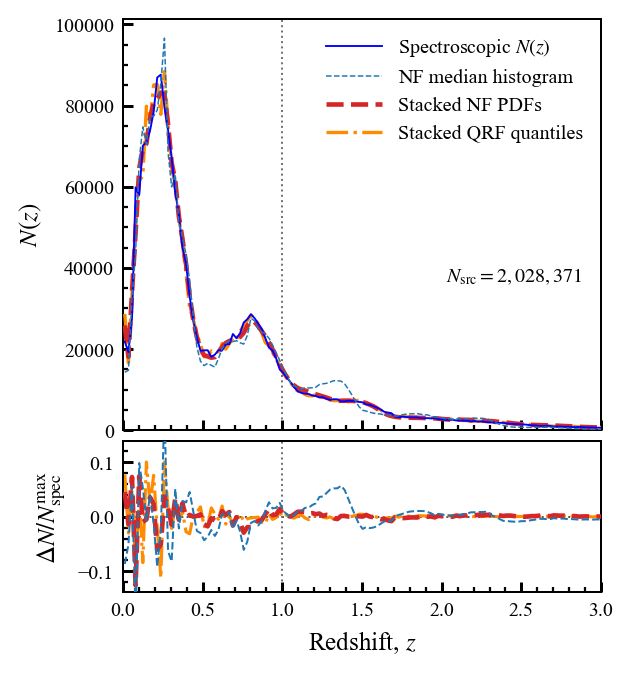

In [171]:

# ============================================================
# show the full N(z) with NF,QRF and NF,.comparing with Spec N(z)
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",

    "font.size": 9,
    "axes.labelsize": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    "axes.linewidth": 0.8,

    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,

    "legend.frameon": False,
})

# ============================================================
# Prepare data
# ============================================================

# Convert to numpy arrays
Nz_spec = np.asarray(nspec2, dtype=float)
Nz_nf = np.asarray(out["Nz_good"], dtype=float)
Nz_qrf = np.asarray(npred_qrf, dtype=float)

# Bin centres
# Assuming z_edges contains histogram edges
z_centres = 0.5 * (z_edges[:-1] + z_edges[1:])

# Use only the common valid length
n_bin = min(
    len(z_centres),
    len(Nz_spec),
    len(Nz_nf),
    len(Nz_qrf),
)

z_plot = z_centres[:n_bin]
Nz_spec = Nz_spec[:n_bin]
Nz_nf = Nz_nf[:n_bin]
Nz_qrf = Nz_qrf[:n_bin]
Nz_zmedian = np.histogram(z_median, bins=z_edges)[0]
# Remove non-finite values if any
valid = (
    np.isfinite(z_plot)
    & np.isfinite(Nz_spec)
    & np.isfinite(Nz_nf)
    & np.isfinite(Nz_qrf)
)

z_plot = z_plot[valid]
Nz_spec = Nz_spec[valid]
Nz_nf = Nz_nf[valid]
Nz_qrf = Nz_qrf[valid]

# ============================================================
# Residuals
#
# Peak-normalized residual:
#
# Delta N(z) / N_spec,max
#
# This is more stable than dividing by N_spec(z), especially
# near the low-count tails.
# ============================================================

spec_peak = np.nanmax(Nz_spec)

if not np.isfinite(spec_peak) or spec_peak <= 0:
    raise ValueError("The spectroscopic N(z) has no positive finite peak.")

res_nf = (Nz_nf - Nz_spec) / spec_peak
res_qrf = (Nz_qrf - Nz_spec) / spec_peak
res_zmedian = (Nz_zmedian - Nz_spec) / spec_peak
# Symmetric residual range
res_limit = 1.10 * np.nanmax(
    np.abs(np.concatenate([res_nf, res_qrf]))
)

# Optional: prevent a single extreme bin from making the panel too broad
# Uncomment and choose a suitable value if required.
# res_limit = min(res_limit, 0.40)

# ============================================================
# Figure
# ============================================================

fig, (ax, ax_res) = plt.subplots(
    2,
    1,
    figsize=(3.32, 3.75),   # MNRAS single-column width
    dpi=180,
    sharex=True,
    gridspec_kw={
        "height_ratios": [3.0, 1.1],
        "hspace": 0.04,
    },
)

# ------------------------------------------------------------
# Main panel
# ------------------------------------------------------------

ax.plot(
    z_plot,
    Nz_spec,
    color="blue",
    lw=0.75,
    ls="-",
    label=r"Spectroscopic $N(z)$",
    zorder=5,
)
ax.plot(
    z_plot,
    Nz_zmedian,
    lw=0.60,
    ls="--",
    label=r"NF median histogram",
    zorder=5,
)

ax.plot(
    z_plot,
    Nz_nf,
    color="tab:red",
    lw=1.85,
    ls="--",
    label=r"Stacked NF PDFs",
    zorder=4,
)

ax.plot(
    z_plot,
    Nz_qrf,
    color="darkorange",
    lw=1.35,
    ls="-.",
    label=r"Stacked QRF quantiles",
    zorder=3,
)

ax.set_ylabel(r"$N(z)$")
ax.set_xlim(0.0, 3)
ax_res.set_xlim(0.0,3)
ax.set_ylim(bottom=0)

ax.legend(
    loc="upper right",
    handlelength=2.8,
    borderaxespad=0.5,
)

ax.text(
    0.96,
    0.35,
    rf"$N_{{\rm src}}={int(np.sum(Nz_qrf)):,}$",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=8,
)

# ------------------------------------------------------------
# Residual panel
# ------------------------------------------------------------

ax_res.axhline(
    0.0,
    color="0.35",
    lw=0.8,
    ls=":",
    zorder=1,
)

ax_res.plot(
    z_plot,
    res_nf,
    color="tab:red",
    lw=1.85,
    ls="--",
    label=r"NF $-$ spec-$z$",
    zorder=3,
)
ax_res.plot(
    z_plot,
    res_zmedian,
    lw=0.80,
    ls="--",
    label=r"NF $z_{{\rm median}}$ ",
    zorder=3,
)
ax_res.plot(
    z_plot,
    res_qrf,
    color="darkorange",
    lw=1.25,
    ls="-.",
    label=r"QRF $-$ spec-$z$",
    zorder=2,
)

ax_res.set_xlabel(r"Redshift, $z$")
ax_res.set_ylabel(
    r"$\Delta N/N_{\rm spec}^{\rm max}$"
)

ax_res.set_ylim(
    -res_limit,
    res_limit,
)

# ============================================================
# Tick formatting
# ============================================================

for axis in (ax, ax_res):
    axis.tick_params(
        which="both",
        direction="in",
        top=False,
        right=False,
    )

    axis.xaxis.set_minor_locator(AutoMinorLocator())
    axis.yaxis.set_minor_locator(AutoMinorLocator())

ax.tick_params(labelbottom=False)

# Optional vertical reference line at the high-z boundary
# Uncomment if z=1.0 is a deliberate model/sample cut.
# for axis in (ax, ax_res):
#     axis.axvline(
#         1.0,
#         color="0.6",
#         lw=0.7,
#         ls=":",
#         zorder=0,
#     )
for axis in (ax, ax_res):
    axis.axvline(
        1.0,
        color="0.45",
        lw=0.8,
        ls=":",
        zorder=1,
    )
fig.subplots_adjust(
    left=0.18,
    right=0.98,
    bottom=0.13,
    top=0.98,
)

# ============================================================
# Save
# ============================================================

fig.savefig(
    "Nz_NF_QRF_residual_MNRAS.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "Nz_NF_QRF_residual_MNRAS.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 12. NF and QRFtomographic $N(z)$
Tomographic samples are selected by the NF posterior median in 8 bins: $(0.0,0.2)$, $(0.2,0.4)$, $(0.4,0.6)$, $(0.6,0.8)$, $(0.8,1.0)$, $(1.0,1.6)$ $(1.6,2.5)$,and $(2.5,4.5)$.


In [50]:
def run_tomographic_nz(z_median, zs, x2_flow):
    edges_low = np.linspace(0, 1.2, 201)
    edges_high = np.linspace(0, 5.0, 251)
    tomo_edges = [0.0, 0.2, 0.4,0.6, 0.8, 1.0, 1.6, 2.5, 4.5]
    results = []

    for i, (lo, hi) in enumerate(zip(tomo_edges[:-1], tomo_edges[1:])):
        mask = (z_median >= lo) & (z_median < hi)
        edges = edges_low if i < 5 else edges_high
        z = (edges[1:] + edges[:-1]) / 2

        hist = np.array([
            np.histogram(x, bins=edges, density=True)[0]
            for x in x2_flow[mask]
        ])

        pred = pipeline_pdf_to_quantiles_mask_stack(
            hist, edges, z95_cut=0., z50_cut=0., width_bins=3
        )["Nz_good"]

        spec = np.histogram(zs[mask], bins=edges)[0]
        median = np.histogram(z_median[mask], bins=edges)[0]
        comp = compare_nz(z, pred, spec, use_counts_for_chi2=True)

        results.append((z, pred, spec, median, comp))

    return results
def reconstruct_qrf_tomographic_nz(
    y_pred_q, z_edges_list,
    tomographic_edges=[0.0, 0.2, 0.4,0.6, 0.8, 1.0, 1.6, 2.5, 4.5],
    quantile_levels=None, y_test=None,
    chunk_size=100_000, renormalize_within_range=False
):
    n_gal, n_q = y_pred_q.shape
    tomo = np.asarray(tomographic_edges, dtype=np.float32)

    levels = (
        np.asarray(quantile_levels, dtype=np.float32)
        if quantile_levels is not None
        else np.linspace(.01, .99, n_q, dtype=np.float32)
    )
    mid = np.argmin(np.abs(levels - .5))

    if len(z_edges_list) != len(tomo) - 1 or not np.isclose(levels[mid], .5):
        raise ValueError("Check tomographic edges and quantile levels.")

    bins = []
    for i, edge in enumerate(z_edges_list):
        edge = np.asarray(edge, dtype=np.float32)
        bins.append(dict(
            bin_index=i,
            selection_low=float(tomo[i]),
            selection_high=float(tomo[i + 1]),
            z_edges=edge,
            z_centres=(edge[:-1] + edge[1:]) / 2,
            nqrf=np.zeros(len(edge) - 1),
            nmedian=np.zeros(len(edge) - 1, dtype=int),
            nspec=np.zeros(len(edge) - 1, dtype=int) if y_test is not None else None,
            n_gal=0,
            n_valid_pdf=0
        ))

    if y_test is not None:
        y_test = np.asarray(y_test).ravel()

    for start in range(0, n_gal, chunk_size):
        q = np.asarray(y_pred_q[start:start + chunk_size], dtype=np.float32)
        med = q[:, mid]

        for i, b in enumerate(bins):
            mask = (med >= tomo[i]) & (
                (med <= tomo[i + 1]) if i == len(bins) - 1
                else (med < tomo[i + 1])
            )
            if not mask.any():
                continue

            edge = b["z_edges"]
            b["n_gal"] += int(mask.sum())
            b["nmedian"] += np.histogram(med[mask], bins=edge)[0]

            if y_test is not None:
                b["nspec"] += np.histogram(
                    y_test[start:start + len(q)][mask], bins=edge
                )[0]

            values = q[mask]
            valid = np.isfinite(values) & (values >= edge[0]) & (values <= edge[-1])
            n_valid = valid.sum(axis=1)
            good = n_valid > 0

            b["n_valid_pdf"] += int(good.sum())
            if not good.any():
                continue

            values, valid, n_valid = values[good], valid[good], n_valid[good]
            idx = np.clip(
                np.searchsorted(edge, values[valid], side="right") - 1,
                0, len(edge) - 2
            )
            weights = (
                np.repeat(1. / n_valid, n_valid)
                if renormalize_within_range
                else np.full(len(idx), 1. / n_q)
            )

            b["nqrf"] += np.bincount(
                idx, weights=weights, minlength=len(edge) - 1
            )

    return dict(
        selection_variable="QRF posterior median",
        quantile_levels=levels,
        median_index=int(mid),
        tomographic_edges=tomo,
        renormalize_within_range=renormalize_within_range,
        bins=bins
    )

In [51]:
results= run_tomographic_nz(z_median, zs, x2_flow)

In [52]:
z_edges_low = np.linspace(0.0, 1.2, 201)
z_edges_high = np.linspace(0.0, 5.0, 251)

In [53]:
z_edges1 = z_edges_low
z_edges2 = z_edges_low
z_edges3 = z_edges_low
z_edges4 = z_edges_low
z_edges5=z_edges_low
z_edges6 = z_edges_high
z_edges7 = z_edges_high
z_edges8 = z_edges_high
z_edges_list = [
    z_edges1,
    z_edges2,
    z_edges3,
    z_edges4,
    z_edges5,
    z_edges6,
    z_edges7,
    z_edges8,
    
]

In [54]:

mask_photo1=(z_median >= 0.0) & (z_median < 0.2)
mask_photo2=(z_median >= 0.2) & (z_median < 0.4)
mask_photo3=(z_median >= 0.4) & (z_median < 0.6)
mask_photo4=(z_median >= 0.6) & (z_median < 0.8)
mask_photo5=(z_median >= 0.8) & (z_median < 1.0)
mask_photo6=(z_median >= 1.0) & (z_median < 1.6)
mask_photo7=(z_median >= 1.6) & (z_median < 2.5)
mask_photo8=(z_median >= 2.5)


In [55]:
zbins1, npred1, nspec1,nz_median1, comp1 = results[0]
zbins2, npred2, nspec2,nz_median2, comp2 = results[1]
zbins3, npred3, nspec3,nz_median3, comp3 = results[2]
zbins4, npred4, nspec4,nz_median4, comp4 = results[3]
zbins5, npred5, nspec5, nz_median5,comp5 = results[4]
zbins6, npred6, nspec6,nz_median6, comp6 = results[5]
zbins7, npred7, nspec7, nz_median7,comp7 = results[6]
zbins8, npred8, nspec8, nz_median8,comp8 = results[7]

In [56]:
comp8

{'mean_pred': 2.5745016032544115,
 'mean_spec': 2.671088775774308,
 'delta_mean': -0.09658717251989657,
 'rel_delta_mean': -0.02631022522726227,
 'sigma_pred': 0.9241127273342558,
 'sigma_spec': 0.8942383206228506,
 'delta_sigma': 0.029874406711405177,
 'rel_delta_sigma': 0.03340765657481241,
 'rmse': 12.671721460551208,
 'chi2': 96474355036103.67,
 'wasserstein_w1': 0.09658717251989746,
 'js_divergence': 0.010950953611907194,
 'overlap': 0.9111019031856575}

In [57]:
results_cal = run_tomographic_nz(z_median_cal, zs, x2_flow_cal)

In [58]:
zbins1_cal, npred1_cal, nspec1_cal,nz_median_cal1, comp1_cal = results_cal[0]
zbins2_cal, npred2_cal, nspec2_cal,nz_median_cal2, comp2_cal = results_cal[1]
zbins3_cal, npred3_cal, nspec3_cal, nz_median_cal3,comp3_cal = results_cal[2]
zbins4_cal, npred4_cal, nspec4_cal, nz_median_cal4,comp4_cal = results_cal[3]
zbins5_cal, npred5_cal, nspec5_cal, nz_median_cal5,comp5_cal = results_cal[4]
zbins6_cal, npred6_cal, nspec6_cal, nz_median_cal6,comp6_cal = results_cal[5]
zbins7_cal, npred7_cal, nspec7_cal,nz_median_cal7, comp7_cal = results_cal[6]
zbins8_cal, npred8_cal, nspec8_cal, nz_median_cal8,comp8_cal = results_cal[7]

In [59]:
comp8_cal

{'mean_pred': 2.6363054274358486,
 'mean_spec': 2.671176673567978,
 'delta_mean': -0.03487124613212922,
 'rel_delta_mean': -0.009498656488857624,
 'sigma_pred': 0.895345139787769,
 'sigma_spec': 0.8942498210362927,
 'delta_sigma': 0.0010953187514762819,
 'rel_delta_sigma': 0.001224846486641711,
 'rmse': 11.526240977626026,
 'chi2': 85773155834547.58,
 'wasserstein_w1': 0.035671187045370166,
 'js_divergence': 0.010367917051273365,
 'overlap': 0.9177751519125723}

In [67]:
tomography_qrf = reconstruct_qrf_tomographic_nz(
    y_pred_q=y_pred_q,
    y_test=zspec_qrf,
    z_edges_list=z_edges_list,
    tomographic_edges=[
        0.0,
        0.2,
        0.4,
        0.6,
        0.8,
        1.0,
        1.6,
        2.5,
        4.5
    ],
    quantile_levels=np.linspace(
        0.01,
        0.99,
        99,
    ),
    chunk_size=100_000,
    renormalize_within_range=False,
)

In [68]:
bin1 = tomography_qrf["bins"][0]
bin2 = tomography_qrf["bins"][1]
bin3 = tomography_qrf["bins"][2]
bin4 = tomography_qrf["bins"][3]
bin5 = tomography_qrf["bins"][4]
bin6 = tomography_qrf["bins"][5]
bin7 = tomography_qrf["bins"][6]
bin8 = tomography_qrf["bins"][7]
# QRF stacked N(z)
nqrf1 = bin1["nqrf"]
nqrf2 = bin2["nqrf"]
nqrf3 = bin3["nqrf"]
nqrf4 = bin4["nqrf"]
nqrf5 = bin5["nqrf"]
nqrf6 = bin6["nqrf"]
nqrf7 = bin7["nqrf"]
nqrf8 = bin8["nqrf"]
# Histogram centres
z_centres1 = bin1["z_centres"]
z_centres2 = bin2["z_centres"]
z_centres3 = bin3["z_centres"]
z_centres4 = bin4["z_centres"]
z_centres5 = bin5["z_centres"]
z_centres6 = bin6["z_centres"]
z_centres7 = bin7["z_centres"]
z_centres8 = bin8["z_centres"]

# QRF median histograms
nmedian1 = bin1["nmedian"]
nmedian2 = bin2["nmedian"]
nmedian3 = bin3["nmedian"]
nmedian4 = bin4["nmedian"]
nmedian5 = bin5["nmedian"]
nmedian6 = bin6["nmedian"]
nmedian7 = bin7["nmedian"]
nmedian8 = bin8["nmedian"]
# Spectroscopic references, provided y_test=zs was passed
nspec_qrf1 = bin1["nspec"]
nspec_qrf2 = bin2["nspec"]
nspec_qrf3 = bin3["nspec"]
nspec_qrf4 = bin4["nspec"]
nspec_qrf5 = bin5["nspec"]
nspec_qrf6 = bin6["nspec"]
nspec_qrf7 = bin7["nspec"]
nspec_qrf8 = bin8["nspec"]

In [69]:
compare_nz(z_centres8,nqrf8,nspec_qrf8)

{'mean_pred': 2.567912803607844,
 'mean_spec': 2.8858263623097122,
 'delta_mean': -0.3179135587018682,
 'rel_delta_mean': -0.08181362960153019,
 'sigma_pred': 1.0192453036665448,
 'sigma_spec': 0.8845747938807127,
 'delta_sigma': 0.13467050978583206,
 'rel_delta_sigma': 0.1522432141605798,
 'rmse': 21.057912983350793,
 'chi2': 116584430163510.12,
 'wasserstein_w1': 0.31791560927008716,
 'js_divergence': 0.03754595773005653,
 'overlap': 0.7873146444424839}

In [70]:
for result_bin in tomography_qrf["bins"]:
    print(
        f"Bin {result_bin['bin_index'] + 1}: "
        f"{result_bin['selection_low']:.3f} <= z_median "
        f"< {result_bin['selection_high']:.3f}, "
        f"N_gal = {result_bin['n_gal']:,}, "
        f"N_valid = {result_bin['n_valid_pdf']:,}"
    )

Bin 1: 0.000 <= z_median < 0.200, N_gal = 450,953, N_valid = 450,953
Bin 2: 0.200 <= z_median < 0.400, N_gal = 626,204, N_valid = 626,204
Bin 3: 0.400 <= z_median < 0.600, N_gal = 168,121, N_valid = 168,121
Bin 4: 0.600 <= z_median < 0.800, N_gal = 196,259, N_valid = 196,259
Bin 5: 0.800 <= z_median < 1.000, N_gal = 199,255, N_valid = 199,255
Bin 6: 1.000 <= z_median < 1.600, N_gal = 264,162, N_valid = 264,162
Bin 7: 1.600 <= z_median < 2.500, N_gal = 116,445, N_valid = 116,445
Bin 8: 2.500 <= z_median < 4.500, N_gal = 6,970, N_valid = 6,970


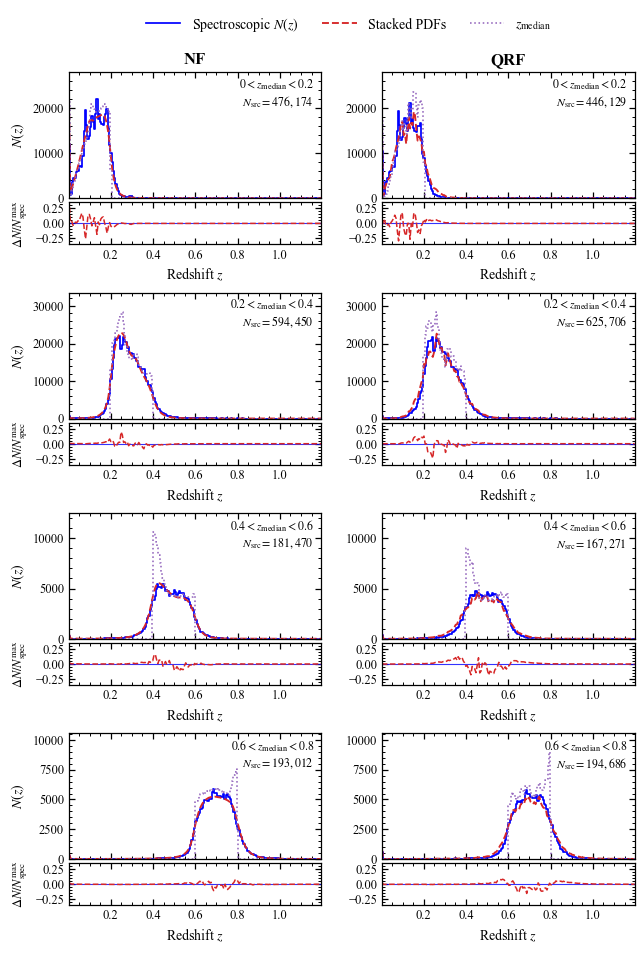

In [71]:


# ============================================================
# 1. MNRAS plotting style
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
})

# ============================================================
# 2. Input data
# Each tuple contains:
# (z_bin_centres, stacked_Nz, spectroscopic_Nz, selected_zmedian)
# ============================================================

nf_data = [
    (zbins1, npred1, nspec1,nz_median1 ),
    (zbins2, npred2, nspec2, nz_median2),
    (zbins3, npred3, nspec3, nz_median3),
    (zbins4, npred4, nspec4, nz_median4),
]

# Replace these names with your QRF variables.
qrf_data = [
    (z_centres1, nqrf1, nspec_qrf1,
   nmedian1),
    (z_centres2, nqrf2, nspec_qrf2,
     nmedian2),
    (z_centres3, nqrf3, nspec_qrf3,
    nmedian3),
    (z_centres4, nqrf4, nspec_qrf4,
     nmedian4),
]

# Tomographic selection boundaries
z_ranges = [
    (0.0, 0.2),
    (0.2, 0.4),
    (0.4, 0.6),
    (0.6, 0.8),
]

# ============================================================
# 3. Helper functions
# ============================================================

def get_edges(z):
    """Convert monotonically increasing bin centres to edges."""
    z = np.asarray(z, dtype=float)

    if len(z) < 2 or np.any(np.diff(z) <= 0):
        raise ValueError("z must contain increasing bin centres.")

    mid = 0.5 * (z[:-1] + z[1:])

    return np.r_[
        z[0] - (mid[0] - z[0]),
        mid,
        z[-1] + (z[-1] - mid[-1])
    ]


def prepare_data(data):
    z, nz_pred, nz_spec, zmed = data

    z = np.asarray(z, dtype=float)
    nz_pred = np.asarray(nz_pred, dtype=float)
    nz_spec = np.asarray(nz_spec, dtype=float)
    nz_median= np.asarray(zmed, dtype=float)

    if not (len(z) == len(nz_pred) == len(nz_spec)):
        raise ValueError("z, predicted Nz and spec Nz lengths differ.")

    edges = get_edges(z)

    

    norm = np.max(nz_spec)

    if norm <= 0:
        raise ValueError("Spectroscopic Nz must have positive maximum.")

    residual = (nz_pred - nz_spec) / norm

    return {
        "z": z,
        "spec": nz_spec,
        "pred": nz_pred,
        "median": nz_median,
        "residual": residual,
        "n_src": int(np.sum(nz_pred)),
    }


# ============================================================
# 4. Figure layout: 4 rows x 2 columns
# Each cell: Nz (top) + residual (bottom)
# ============================================================

fig = plt.figure(figsize=(6.5, 9.8))

outer = fig.add_gridspec(
    nrows=4,
    ncols=2,
    left=0.11,
    right=0.98,
    bottom=0.07,
    top=0.92,
    wspace=0.24,
    hspace=0.28
)

methods = ["NF", "QRF"]
all_data = [nf_data, qrf_data]

legend_handles = None

for i in range(4):

    # Prepare both methods before setting shared y limits
    row_data = [
        prepare_data(nf_data[i]),
        prepare_data(qrf_data[i])
    ]

    # Identical axis ranges for NF and QRF in each row
    ymax = max(
        np.nanmax(np.r_[
            d["spec"], d["pred"], d["median"]
        ])
        for d in row_data
    ) * 1.18

    xmin = min(np.min(d["z"]) for d in row_data)
    xmax = max(np.max(d["z"]) for d in row_data)

    for j in range(2):

        d = row_data[j]
        method = methods[j]

        inner = outer[i, j].subgridspec(
            2, 1,
            height_ratios=[3, 1],
            hspace=0.05
        )

        ax = fig.add_subplot(inner[0])
        axr = fig.add_subplot(inner[1], sharex=ax)

        z = d["z"]

        # ----------------------------------------------------
        # Main Nz panel
        # ----------------------------------------------------

        line_spec, = ax.step(
            z, d["spec"],
            where="mid",
            color="blue",
            lw=1.25,
            label=r"Spectroscopic $N(z)$"
        )

        line_pred, = ax.plot(
            z, d["pred"],
            color="tab:red",
            ls="--",
            lw=1.35,
            label="Stacked PDFs"
        )

        line_med, = ax.step(
            z, d["median"],
            where="mid",
            color="tab:purple",
            ls=":",
            lw=1.15,
            label=r"$z_{\rm median}$"
        )

        if legend_handles is None:
            legend_handles = [
                line_spec, line_pred, line_med
            ]

        ax.set_ylim(0, ymax)
        ax.set_xlim(xmin, xmax)

        if j == 0:
            ax.set_ylabel(r"$N(z)$")

        if i == 0:
            ax.set_title(
                method,
                fontsize=12,
                fontweight="bold",
                pad=6
            )

        zmin, zmax = z_ranges[i]

        ax.text(
            0.97, 0.96,
            rf"${zmin:g} < z_{{\rm median}} < {zmax:g}$"
            "\n"
            rf"$N_{{\rm src}}={d['n_src']:,}$",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=8.5
        )

        ax.tick_params(
            which="major",
            length=4,
            width=0.9
        )

        ax.tick_params(
            which="minor",
            length=2,
            width=0.7
        )

        ax.xaxis.set_minor_locator(AutoMinorLocator())
        ax.yaxis.set_minor_locator(AutoMinorLocator())

        plt.setp(ax.get_xticklabels(), visible=False)

        # ----------------------------------------------------
        # Residual panel
        # ----------------------------------------------------

        axr.axhline(
            0,
            color="blue",
            lw=0.8,
            alpha=0.8
        )

        axr.plot(
            z,
            d["residual"],
            color="tab:red",
            ls="--",
            lw=1.1
        )

        axr.set_ylim(-0.35, 0.35)
        axr.set_xlim(xmin, xmax)

        if j == 0:
            axr.set_ylabel(
                r"$\Delta N/N_{\rm spec}^{\rm max}$",
                fontsize=9
            )

        axr.set_xlabel(r"Redshift $z$")

        axr.tick_params(
            which="major",
            length=4,
            width=0.9
        )

        axr.tick_params(
            which="minor",
            length=2,
            width=0.7
        )

        axr.xaxis.set_minor_locator(AutoMinorLocator())
        axr.yaxis.set_minor_locator(AutoMinorLocator())

# ============================================================
# 5. Shared legend
# ============================================================

fig.legend(
    legend_handles,
    [
        r"Spectroscopic $N(z)$",
        "Stacked PDFs",
        r"$z_{\rm median}$"
    ],
    loc="upper center",
    bbox_to_anchor=(0.54, 0.991),
    ncol=3,
    frameon=False,
    fontsize=10,
    columnspacing=1.7,
    handlelength=2.5
)

# ============================================================
# 6. Save
# ============================================================

plt.savefig(
    "NF_QRF_tomographic_comparison.pdf",
    bbox_inches="tight",
    pad_inches=0.04
)

plt.show()


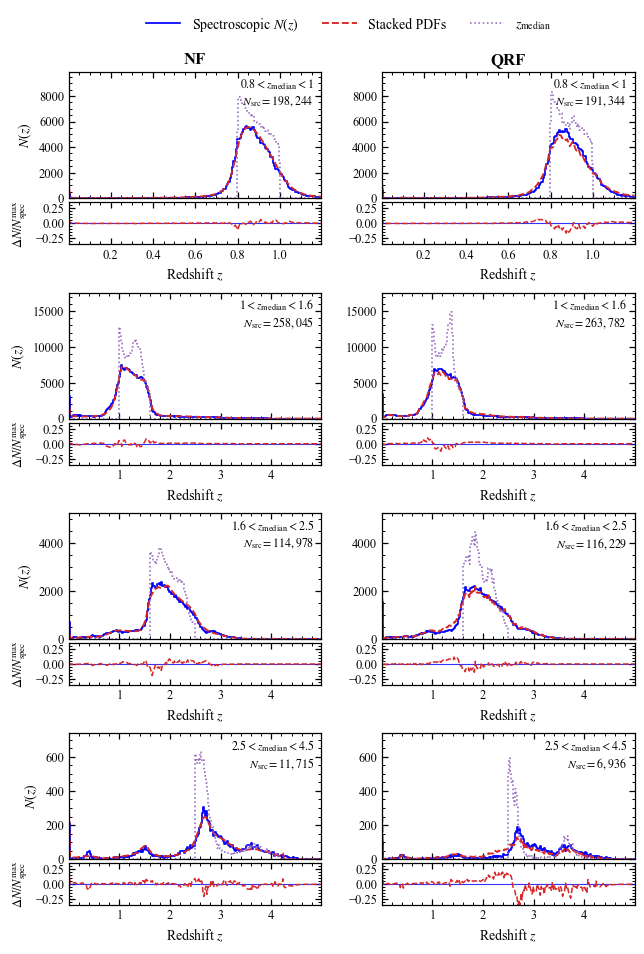

In [72]:

from matplotlib.ticker import AutoMinorLocator
# ============================================================
# 1. MNRAS plotting style
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
})
# ============================================================
# 2. Input data
# Each tuple contains:
# (z_bin_centres, stacked_Nz, spectroscopic_Nz, selected_zmedian)
# ============================================================
nf_data = [
    (zbins5, npred5, nspec5,nz_median5 ),
    (zbins6, npred6, nspec6, nz_median6),
    (zbins7, npred7, nspec7, nz_median7),
    (zbins8, npred8, nspec8, nz_median8),
]
# Replace these names with your QRF variables.
qrf_data = [
    (z_centres5, nqrf5, nspec_qrf5,
   nmedian5),
    (z_centres6, nqrf6, nspec_qrf6,
     nmedian6),
    (z_centres7, nqrf7, nspec_qrf7,
    nmedian7),
    (z_centres8, nqrf8, nspec_qrf8,
     nmedian8),
]
# Tomographic selection boundaries
z_ranges = [
    (0.8, 1.0),
    (1.0, 1.6),
    (1.6, 2.5),
    (2.5, 4.5),
]
# ============================================================
# 3. Helper functions
# ============================================================
def get_edges(z):
    """Convert monotonically increasing bin centres to edges."""
    z = np.asarray(z, dtype=float)
    if len(z) < 2 or np.any(np.diff(z) <= 0):
        raise ValueError("z must contain increasing bin centres.")
    mid = 0.5 * (z[:-1] + z[1:])
    return np.r_[
        z[0] - (mid[0] - z[0]),
        mid,
        z[-1] + (z[-1] - mid[-1])
    ]
def prepare_data(data):
    z, nz_pred, nz_spec, zmed = data
    z = np.asarray(z, dtype=float)
    nz_pred = np.asarray(nz_pred, dtype=float)
    nz_spec = np.asarray(nz_spec, dtype=float)
    nz_median= np.asarray(zmed, dtype=float)
    if not (len(z) == len(nz_pred) == len(nz_spec)):
        raise ValueError("z, predicted Nz and spec Nz lengths differ.")
    edges = get_edges(z)    
    norm = np.max(nz_spec)
    if norm <= 0:
        raise ValueError("Spectroscopic Nz must have positive maximum.")

    residual = (nz_pred - nz_spec) / norm
    return {
        "z": z,
        "spec": nz_spec,
        "pred": nz_pred,
        "median": nz_median,
        "residual": residual,
        "n_src": int(np.sum(nz_pred)),
    }
# ============================================================
# 4. Figure layout: 4 rows x 2 columns
# Each cell: Nz (top) + residual (bottom)
# ============================================================
fig = plt.figure(figsize=(6.5, 9.8))
outer = fig.add_gridspec(
    nrows=4,
    ncols=2,
    left=0.11,
    right=0.98,
    bottom=0.07,
    top=0.92,
    wspace=0.24,
    hspace=0.28
)
methods = ["NF", "QRF"]
all_data = [nf_data, qrf_data]
legend_handles = None
for i in range(4):
    # Prepare both methods before setting shared y limits
    row_data = [
        prepare_data(nf_data[i]),
        prepare_data(qrf_data[i])
    ]
    # Identical axis ranges for NF and QRF in each row
    ymax = max(
        np.nanmax(np.r_[
            d["spec"], d["pred"], d["median"]
        ])
        for d in row_data
    ) * 1.18
    xmin = min(np.min(d["z"]) for d in row_data)
    xmax = max(np.max(d["z"]) for d in row_data)
    for j in range(2):
        d = row_data[j]
        method = methods[j]

        inner = outer[i, j].subgridspec(
            2, 1,
            height_ratios=[3, 1],
            hspace=0.05
        )
        ax = fig.add_subplot(inner[0])
        axr = fig.add_subplot(inner[1], sharex=ax)
        z = d["z"]
        # ----------------------------------------------------
        # Main Nz panel
        # ----------------------------------------------------
        line_spec, = ax.step(
            z, d["spec"],
            where="mid",
            color="blue",
            lw=1.25,
            label=r"Spectroscopic $N(z)$"
        )
        line_pred, = ax.plot(
            z, d["pred"],
            color="tab:red",
            ls="--",
            lw=1.35,
            label="Stacked PDFs"
        )
        line_med, = ax.step(
            z, d["median"],
            where="mid",
            color="tab:purple",
            ls=":",
            lw=1.15,
            label=r"$z_{\rm median}$"
        )
        if legend_handles is None:
            legend_handles = [
                line_spec, line_pred, line_med
            ]
        ax.set_ylim(0, ymax)
        ax.set_xlim(xmin, xmax)
        if j == 0:
            ax.set_ylabel(r"$N(z)$")
        if i == 0:
            ax.set_title(
                method,
                fontsize=12,
                fontweight="bold",
                pad=6
            )
        zmin, zmax = z_ranges[i]
        ax.text(
            0.97, 0.96,
            rf"${zmin:g} < z_{{\rm median}} < {zmax:g}$"
            "\n"
            rf"$N_{{\rm src}}={d['n_src']:,}$",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=8.5
        )
        ax.tick_params(
            which="major",
            length=4,
            width=0.9
        )
        ax.tick_params(
            which="minor",
            length=2,
            width=0.7
        )
        ax.xaxis.set_minor_locator(AutoMinorLocator())
        ax.yaxis.set_minor_locator(AutoMinorLocator())
        plt.setp(ax.get_xticklabels(), visible=False)
        # ----------------------------------------------------
        # Residual panel
        # ----------------------------------------------------
        axr.axhline(
            0,
            color="blue",
            lw=0.8,
            alpha=0.8
        )
        axr.plot(
            z,
            d["residual"],
            color="tab:red",
            ls="--",
            lw=1.1
        )
        axr.set_ylim(-0.35, 0.35)
        axr.set_xlim(xmin, xmax)
        if j == 0:
            axr.set_ylabel(
                r"$\Delta N/N_{\rm spec}^{\rm max}$",
                fontsize=9
            )
        axr.set_xlabel(r"Redshift $z$")
        axr.tick_params(
            which="major",
            length=4,
            width=0.9
        )
        axr.tick_params(
            which="minor",
            length=2,
            width=0.7
        )
        axr.xaxis.set_minor_locator(AutoMinorLocator())
        axr.yaxis.set_minor_locator(AutoMinorLocator())
# ============================================================
# 5. Shared legend
# ============================================================
fig.legend(
    legend_handles,
    [
        r"Spectroscopic $N(z)$",
        "Stacked PDFs",
        r"$z_{\rm median}$"
    ],
    loc="upper center",
    bbox_to_anchor=(0.54, 0.991),
    ncol=3,
    frameon=False,
    fontsize=10,
    columnspacing=1.7,
    handlelength=2.5
)

plt.savefig(
    "NF_QRF_tomographic_comparison2.pdf",
    bbox_inches="tight",
    pad_inches=0.04
)
plt.show()

## 13. top 0.5 percentile $N(z)$
Reconstruct the stacked NF and QRF redshift distributions for the top redshift 0.5 percentile .


In [73]:
quan=np.quantile(qrf_median,0.995)

In [74]:
quan1=np.quantile(z_median,0.995)

In [75]:
bin=qrf_median>quan

In [76]:
bin1=z_median>quan1

In [77]:
z_edges = np.linspace(0.0, 4.5, 250)
z_centres = 0.5 * (z_edges[:-1] + z_edges[1:])

npred_qrf = stack_qrf_quantile_histograms(
        y_pred_q[bin], z_edges)
nspec_qrf=stack_qrf_quantile_histograms(
        zspec_qrf[bin], z_edges)
nmedian_qrf=stack_qrf_quantile_histograms(
        qrf_median[bin], z_edges)

In [78]:
np.min(qrf_median[bin])

2.401547

In [79]:
np.min(z_median[bin1])

2.5535902122037406

In [80]:

npred_nf = stack_qrf_quantile_histograms(
        x2_flow[bin1], z_edges)
nspec_nf=stack_qrf_quantile_histograms(
        zs[bin1], z_edges)
nmedian_rf=stack_qrf_quantile_histograms(
        z_median[bin1], z_edges)

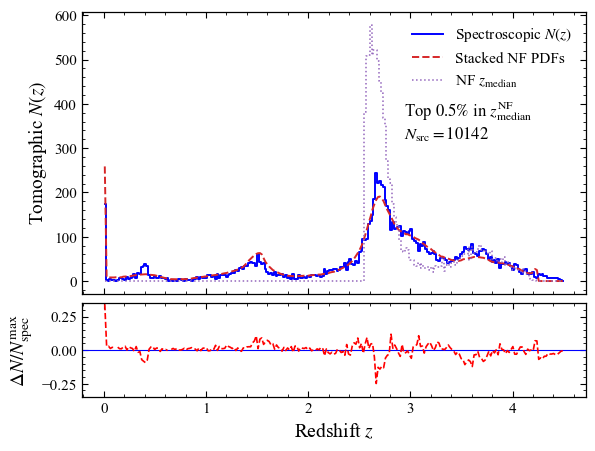

In [81]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})
z = np.asarray(z_centres)
nz_qrf = np.asarray(npred_nf)
nz_spec = np.asarray(nspec_nf)
norm = np.max(nz_spec)
# Convert bin centres to edges
dz = np.median(np.diff(z))
z_edges = np.r_[z - dz / 2, z[-1] + dz / 2]

nz_median=np.asarray(nmedian_rf)

# Residual relative to spectroscopic N(z)
res_qrf = np.divide(
    nz_qrf - nz_spec,
    norm,
    out=np.full_like(nz_spec, np.nan, dtype=float),
    where=nz_spec > 0,
)

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(6.5, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax.step(
    z, nz_spec,
    where="mid",
    color="blue",
    lw=1.4,
    label=r"Spectroscopic $N(z)$"
)

ax.plot(
    z, nz_qrf,
    color="tab:red",
    ls="--",
    lw=1.4,
    label="Stacked NF PDFs"
)

ax.step(
    z, nz_median,
    where="mid",
    color="tab:purple",
    ls=":",
    lw=1.1,
    label=r"NF $z_{\rm median}$"
)

ax.text(
    0.64, 0.69,
    rf"Top $0.5\%$ in $z_{{\rm median}}^{{\rm NF}}$"
    "\n"
    rf"$N_{{\rm src}}={int(np.sum(npred_nf))}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_ylabel(r"Tomographic $N(z)$")
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

axr.axhline(0, color="blue", lw=0.8)

axr.plot(
    z,
    res_qrf,
    color="red",
    ls="--",
    lw=1.2
)
axr.set_xlabel(r"Redshift $z$")
axr.set_ylabel(r"$\Delta N/N_{\rm spec}^{\rm max}$")
axr.set_ylim(-0.35, 0.35)

axr.xaxis.set_minor_locator(AutoMinorLocator())
axr.yaxis.set_minor_locator(AutoMinorLocator())

plt.savefig(
    "QRF_tomographic_Nz_0.006_0.2.pdf",
    bbox_inches="tight"
)
plt.show()

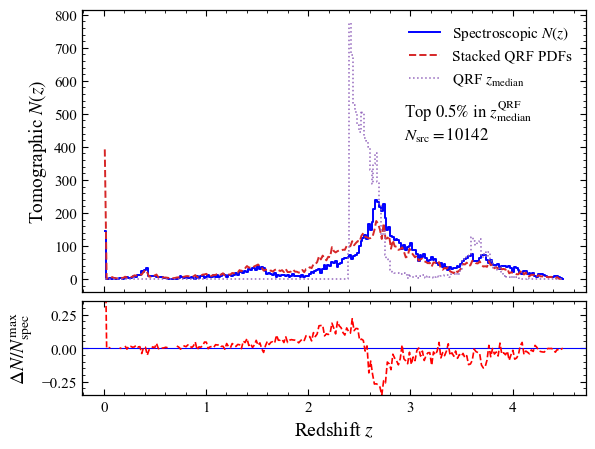

In [82]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})
z = np.asarray(z_centres)
nz_qrf = np.asarray(npred_qrf)
nz_spec = np.asarray(nspec_qrf)
norm = np.max(nz_spec)
# Convert bin centres to edges
dz = np.median(np.diff(z))
z_edges = np.r_[z - dz / 2, z[-1] + dz / 2]

nz_median=np.asarray(nmedian_qrf)

# Residual relative to spectroscopic N(z)
res_qrf = np.divide(
    nz_qrf - nz_spec,
    norm,
    out=np.full_like(nz_spec, np.nan, dtype=float),
    where=nz_spec > 0,
)

fig, (ax, axr) = plt.subplots(
    2, 1,
    figsize=(6.5, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax.step(
    z, nz_spec,
    where="mid",
    color="blue",
    lw=1.4,
    label=r"Spectroscopic $N(z)$"
)

ax.plot(
    z, nz_qrf,
    color="tab:red",
    ls="--",
    lw=1.4,
    label="Stacked QRF PDFs"
)

ax.step(
    z, nz_median,
    where="mid",
    color="tab:purple",
    ls=":",
    lw=1.1,
    label=r"QRF $z_{\rm median}$"
)

ax.text(
    0.64, 0.69,
    rf"Top $0.5\%$ in $z_{{\rm median}}^{{\rm QRF}}$"
    "\n"
    rf"$N_{{\rm src}}={int(np.sum(npred_nf))}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_ylabel(r"Tomographic $N(z)$")
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

axr.axhline(0, color="blue", lw=0.8)

axr.plot(
    z,
    res_qrf,
    color="red",
    ls="--",
    lw=1.2
)
axr.set_xlabel(r"Redshift $z$")
axr.set_ylabel(r"$\Delta N/N_{\rm spec}^{\rm max}$")
axr.set_ylim(-0.35, 0.35)

axr.xaxis.set_minor_locator(AutoMinorLocator())
axr.yaxis.set_minor_locator(AutoMinorLocator())

plt.savefig(
    "QRF_tomographic_Nz_0.006_0.2.pdf",
    bbox_inches="tight"
)
plt.show()

In [83]:
compare_nz(z_centres,npred_nf,nspec_nf)

{'mean_pred': 2.613699545530702,
 'mean_spec': 2.723272918071568,
 'delta_mean': -0.10957337254086585,
 'rel_delta_mean': -0.029429315269646764,
 'sigma_pred': 0.9529131488946945,
 'sigma_spec': 0.9106592713308338,
 'delta_sigma': 0.042253877563860676,
 'rel_delta_sigma': 0.046399217461555106,
 'rmse': 11.913697422615027,
 'chi2': 97033862201036.84,
 'wasserstein_w1': 0.10957337254086504,
 'js_divergence': 0.0124596735414096,
 'overlap': 0.903291898459657}

In [84]:
compare_nz(z_centres,npred_qrf,nspec_qrf)

{'mean_pred': 2.4864868217071825,
 'mean_spec': 2.735058008038531,
 'delta_mean': -0.24857118633134867,
 'rel_delta_mean': -0.06655082352037849,
 'sigma_pred': 0.9292760011815892,
 'sigma_spec': 0.8331838580381234,
 'delta_sigma': 0.0960921431434657,
 'rel_delta_sigma': 0.11533125878090268,
 'rmse': 25.122212390161266,
 'chi2': 96080268073957.48,
 'wasserstein_w1': 0.24857118633134864,
 'js_divergence': 0.024317260366485894,
 'overlap': 0.8212039691899528}